# 3.02. A/B-тесты в компаниях

**План занятия**

1. Зачем компании нужна платформа экспериментов.
2. Как устроена типовая платформа глазами аналитика.
3. Сплитование: от `id > 5` к хешу с солью.
4. Качество хеша: почему обычной проверки сплита мало.
5. Параллельность: изоляция, слои, домены и остаточный эффект.
6. Пересечения тестов: ортогональность, аддитивность и что с ними делать.
7. Надёжность платформы: SRM и постоянный контроль.
8. Культура и процесс.
9. Кейсы компаний и чек-лист.

### Библиотеки

Кроме стандартных библиотек нужен `xxhash`. В Colab поставьте его командой `!pip install -q xxhash`.

In [1]:
import hashlib
import zlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
import xxhash
from matplotlib.patches import FancyBboxPatch, Rectangle
from scipy import stats
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
PURPLE, ORANGE = '#8172B3', '#DD8452'
ALPHA = 0.05
Z = stats.norm.ppf(1 - ALPHA / 2)
rng = np.random.default_rng(42)
pd.set_option('display.float_format', lambda v: f'{v:,.4g}')


def draw_box(ax, x, y, width, height, label, color, fontsize=10.5):
    ax.add_patch(FancyBboxPatch((x, y), width, height, boxstyle='round,pad=0,rounding_size=0.02',
                                fc=color, ec='#444444', lw=1.0, zorder=2))
    ax.text(x + width / 2, y + height / 2, label, ha='center', va='center', fontsize=fontsize, zorder=3)


def draw_arrow(ax, start, end, dashed=False):
    ax.annotate('', xy=end, xytext=start, zorder=1, arrowprops=dict(arrowstyle='-|>', color='#444444', lw=1.5,
                                                                    ls='--' if dashed else '-', mutation_scale=16))

## Зачем компании нужна платформа

Пока тестов несколько в квартал, хватает таблицы и аналитика, который считает всё руками. Проблемы начинаются, когда экспериментов становятся десятки и сотни:

* **Заканчивается трафик.** Если каждому тесту выделять свою долю пользователей, очередь растёт, а чувствительность падает.
* **Тесты мешают друг другу.** Две команды меняют один экран, и никто об этом не знает.
* **Ошибки становятся незаметными.** Поломку логирования некому увидеть, если никто не смотрит на каждый тест отдельно.
* **Решения трудно воспроизвести.** Разные аналитики по-разному считают одну метрику.

Платформа решает эти задачи: автоматизирует назначение групп, расчёт метрик и проверки, чтобы запуск теста стоил дёшево, а результату можно было верить.

Масштаб меняется очень быстро. В Ozon за четыре года платформа выросла с двух экспериментов до более чем ста в месяц. В LinkedIn поддержка выросла примерно с 50 экспериментов в день до более чем 400, а метрик с 60 до более чем 1000. В Google после перехода на пересекающиеся эксперименты число экспериментов, запусков и участников выросло почти на порядок. Fabijan и соавторы описывают этот путь в компаниях как четыре стадии: Crawl, Walk, Run и Fly.

Ниже упрощённая история платформы Ozon. Важно не название шагов, а то, что каждый из них снимал ограничение предыдущего.

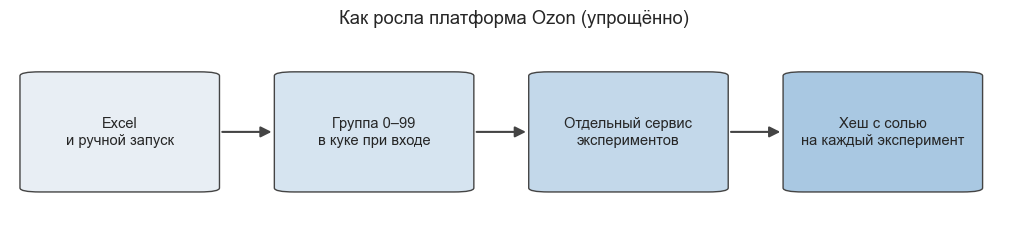

In [2]:
stages = [('Excel\nи ручной запуск', '#E8EEF4'), ('Группа 0–99\nв куке при входе', '#D6E4F0'),
          ('Отдельный сервис\nэкспериментов', '#C3D8EA'), ('Хеш с солью\nна каждый эксперимент', '#A9C8E2')]
fig, ax = plt.subplots(figsize=(13, 2.6))
for i, (label, color) in enumerate(stages):
    draw_box(ax, i * 0.255, 0.2, 0.2, 0.6, label, color)
    if i:
        draw_arrow(ax, (i * 0.255 - 0.055, 0.5), (i * 0.255, 0.5))
ax.set_xlim(-0.01, 1)
ax.set_ylim(0, 1)
ax.axis('off')
ax.set_title('Как росла платформа Ozon (упрощённо)')
plt.show()

## Устройство платформы

Аналитику не нужно знать, как платформа держит нагрузку. Нужно знать, из каких шагов рождаются данные, потому что ошибка на любом шаге превращается в ложный эффект. Схема ниже обобщает описания Kohavi и соавторов, LinkedIn, Ozon и Spotify: в конкретных компаниях блоки называются и делятся по-разному.

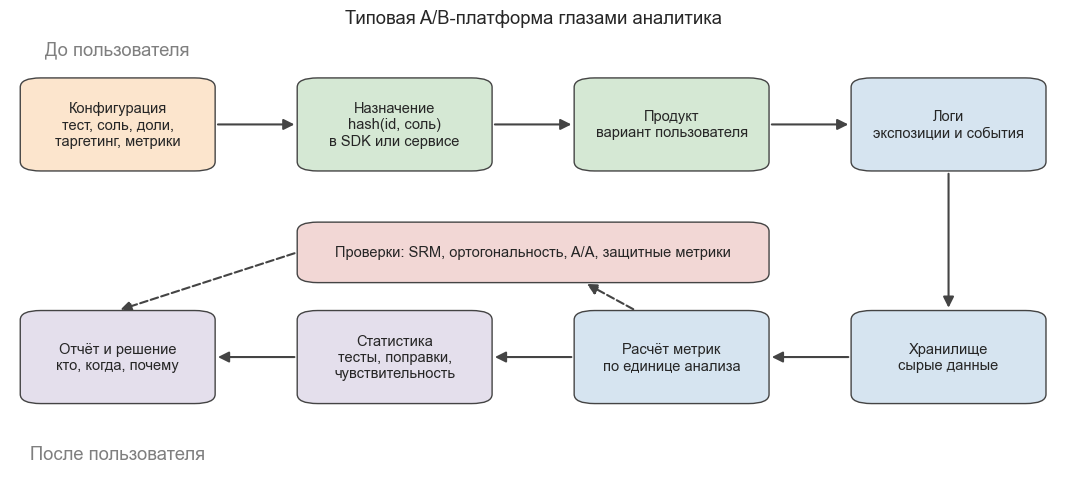

In [3]:
fig, ax = plt.subplots(figsize=(13.5, 5.8))
blocks = {
    'config': (0.0, 0.70, 'Конфигурация\nтест, соль, доли,\nтаргетинг, метрики', '#FCE5CD'),
    'assign': (0.27, 0.70, 'Назначение\nhash(id, соль)\nв SDK или сервисе', '#D5E8D4'),
    'product': (0.54, 0.70, 'Продукт\nвариант пользователя', '#D5E8D4'),
    'log': (0.81, 0.70, 'Логи\nэкспозиции и события', '#D6E4F0'),
    'dwh': (0.81, 0.20, 'Хранилище\nсырые данные', '#D6E4F0'),
    'metrics': (0.54, 0.20, 'Расчёт метрик\nпо единице анализа', '#D6E4F0'),
    'stats': (0.27, 0.20, 'Статистика\nтесты, поправки,\nчувствительность', '#E4DFEC'),
    'report': (0.0, 0.20, 'Отчёт и решение\nкто, когда, почему', '#E4DFEC'),
}
width, height = 0.19, 0.2
for x, y, label, color in blocks.values():
    draw_box(ax, x, y, width, height, label, color)
for start, end in [('config', 'assign'), ('assign', 'product'), ('product', 'log')]:
    draw_arrow(ax, (blocks[start][0] + width, 0.80), (blocks[end][0], 0.80))
draw_arrow(ax, (blocks['log'][0] + width / 2, 0.70), (blocks['dwh'][0] + width / 2, 0.40))
for start, end in [('dwh', 'metrics'), ('metrics', 'stats'), ('stats', 'report')]:
    draw_arrow(ax, (blocks[start][0], 0.30), (blocks[end][0] + width, 0.30))
draw_box(ax, 0.27, 0.46, 0.46, 0.13, 'Проверки: SRM, ортогональность, A/A, защитные метрики', '#F2D7D5')
draw_arrow(ax, (0.6, 0.40), (0.55, 0.46), dashed=True)
draw_arrow(ax, (0.27, 0.525), (0.095, 0.40), dashed=True)
ax.text(0.095, 0.95, 'До пользователя', ha='center', color=GRAY)
ax.text(0.095, 0.08, 'После пользователя', ha='center', color=GRAY)
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(0.04, 1)
ax.axis('off')
ax.set_title('Типовая A/B-платформа глазами аналитика')
plt.show()

| Компонент | Что делает | Что может сломаться |
| :--- | :--- | :--- |
| Конфигурация | Хранит тест, соль, доли, таргетинг, метрики, сроки | Изменили долю на ходу, забыли про соль |
| Назначение | Определяет вариант пользователя | Группа меняется при входе в аккаунт |
| Продукт | Показывает вариант | Вариант ломает логирование или загружается дольше |
| Логи | Пишут факт показа и события | Потери в одном из вариантов, боты |
| Метрики | Считают метрику по единице анализа | Неверное соединение таблиц, разные определения |
| Статистика | Тесты, поправки, снижение дисперсии | Подглядывание, неподходящий критерий |
| Проверки | SRM, ортогональность, защитные метрики | Сигнала нет или ему не верят |

**Три решения, которые влияют на анализ**

* **Вычислять группу или хранить.** Kohavi и соавторы разбирают два подхода. Случайное число с кэшированием требует хранить назначение в базе или куке, и оно теряется при очистке куки. Хеш от пользователя и эксперимента ничего не хранит: группа каждый раз вычисляется заново и получается той же. Ozon прошла этот путь: сначала группа 0–99 выдавалась при авторизации и лежала в куке, потом стала считаться для каждого эксперимента как хеш с солью по модулю 100. Цена ошибки здесь высокая: Delivery Club отказалась от Firebase, потому что около 30% пользователей меняли группу.
* **Где логировать участие.** Пользователя стоит считать участником, только когда он дошёл до места изменения. Иначе эффект размывается на тех, кто его не видел. Но условие должно одинаково работать в обоих вариантах, иначе появится SRM: об этом в разделе про надёжность.
* **Своя платформа или готовая.** Своя нужна при большом трафике, особых единицах рандомизации и строгих требованиях к данным. Готовые продукты вроде GrowthBook, Statsig или Confidence от Spotify закрывают типовые случаи быстрее. Статистика в обоих случаях одна, а значит, проверки из этой лекции нужны и там, и там.

## Деление пользователей на группы

**Система сплитования** — это алгоритм, который распределяет единицы рандомизации по группам. Единицей может быть `user_id`, `device_id`, сессия или что-то ещё. Kohavi и соавторы формулируют главные требования:

1. Пользователи делятся в нужной пропорции, и группы похожи друг на друга.
2. Один пользователь всегда видит один и тот же вариант, в какой бы момент он ни пришёл.
3. Группы разных экспериментов не связаны между собой.

**Почему не взять обычный `random()`?** Он даёт случайную группу, но при следующем заходе выдаст другую. Значит, результат надо где-то хранить, и хранилище придётся спрашивать при каждом запросе к каждому эксперименту. Хотелось бы вычислять группу прямо из `id`, ничего не запоминая.

Первая мысль — простое правило от `id`. Проверим такие правила на базе пользователей с двумя реальными особенностями. Идентификаторы выдаются по порядку, поэтому у старых пользователей они меньше, а метрика у них выше. Кроме того, чётные id выдаёт шард iOS, а нечётные шард Android: так бывает, когда разные сервисы получают свои диапазоны.

Проверяем правила как A/A: воздействия нет, разницы быть не должно.

In [4]:
def md5_int(text: str) -> int:
    return int.from_bytes(hashlib.md5(text.encode()).digest()[:8], 'little')


def hash_ids(ids, salt: str, hash_fn=md5_int) -> np.ndarray:
    """Хеширует пары «соль:id» и возвращает целые числа."""
    return np.array([hash_fn(f'{salt}:{i}') for i in ids], dtype=np.uint64)


N_USERS = 100_000
user_id = np.arange(1_000_000, 1_000_000 + N_USERS)
ios = (user_id % 2 == 0).astype(int)                    # чётные id выдавал шард iOS
tenure = 1 - (user_id - user_id[0]) / N_USERS           # старые пользователи имеют меньшие id
metric = 1 + 0.6 * tenure + 0.3 * ios + rng.normal(0, 1, N_USERS)

splits = {
    'id > медианы': user_id > np.median(user_id),
    'id % 2 == 0': user_id % 2 == 0,
    'hash(id) % 2 == 0': hash_ids(user_id, '') % 2 == 0,
}
rows = {}
for name, test in splits.items():
    res = stats.ttest_ind(metric[test], metric[~test])
    rows[name] = {'Доля теста': test.mean(), 'Разница метрики': metric[test].mean() - metric[~test].mean(), 'p-value': res.pvalue,
                  'Доля iOS в тесте': ios[test].mean(), 'Срок жизни в тесте': tenure[test].mean()}
pd.DataFrame(rows).T

,Доля теста,Разница метрики,p-value,Доля iOS в тесте,Срок жизни в тесте
id > медианы,0.5,-0.3074,0,0.5,0.25
id % 2 == 0,0.5,0.2963,0,1,0.5
hash(id) % 2 == 0,0.4975,0.01064,0.1025,0.4993,0.5005


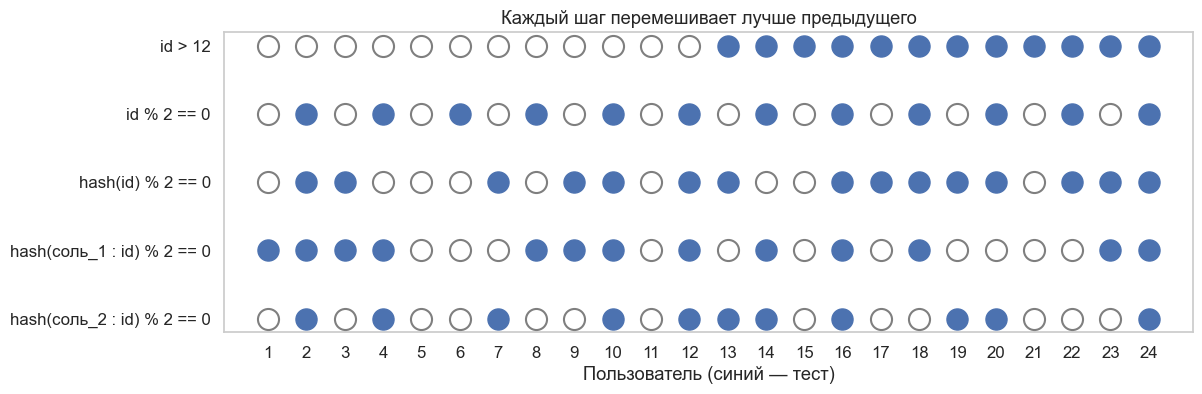

In [5]:
shown = np.arange(1, 25)
schemes = {
    'id > 12': shown > 12,
    'id % 2 == 0': shown % 2 == 0,
    'hash(id) % 2 == 0': hash_ids(shown, '') % 2 == 0,
    'hash(соль_1 : id) % 2 == 0': hash_ids(shown, 'sodium chloride') % 2 == 0,
    'hash(соль_2 : id) % 2 == 0': hash_ids(shown, 'cesium persulfate') % 2 == 0,
}
fig, ax = plt.subplots(figsize=(12.5, 3.9))
for row, (name, test) in enumerate(schemes.items()):
    y = len(schemes) - row
    ax.scatter(shown[test], [y] * test.sum(), s=230, color=BLUE, zorder=3)
    ax.scatter(shown[~test], [y] * (~test).sum(), s=230, color='white', edgecolor=GRAY, lw=1.5, zorder=3)
ax.set_yticks(range(len(schemes), 0, -1), list(schemes))
ax.set_xticks(shown)
ax.set_xlabel('Пользователь (синий — тест)')
ax.grid(False)
ax.set_title('Каждый шаг перемешивает лучше предыдущего')
plt.show()

* **`id > медианы`** сравнивает новых со старыми: разница −0.31 при нулевом эффекте.
* **`id % 2`** делит ровно пополам, но на самом деле сравнивает iOS с Android: разница +0.30.
* **Хеш** делит так, что обе группы похожи на всю базу.

Простые правила ломаются, потому что `id` не случаен: в нём зашита история пользователя. Нам нужно превратить его в число, которое выглядит случайным, но всегда одно и то же для одного `id`. Именно это и делает хеш.

**Хеш-функция** превращает строку любой длины в большое число. Для нас важны три свойства:

* **Детерминированность.** Одна строка всегда даёт одно и то же число. Поэтому группу не надо хранить: её можно вычислить заново где угодно. Так выполняется требование 2.
* **Перемешивание.** Похожие строки дают совершенно непохожие числа. У пользователей 1000123 и 1000124 числа не имеют ничего общего, поэтому порядок регистрации и шард перестают влиять на группу. Так выполняется требование 1.
* **Равномерность.** Все значения встречаются одинаково часто.

Большое число неудобно, поэтому берём остаток от деления, обычно на 100 или 1000. Получается номер **бакета** — маленькой корзины пользователей. Эксперименту выдают нужную долю бакетов: например, бакеты 0–49 становятся тестом, а 50–99 контролем. Так легко задать любую пропорцию: бакеты 0–9 дают 10% трафика.

Посмотрим путь четырёх соседних пользователей.

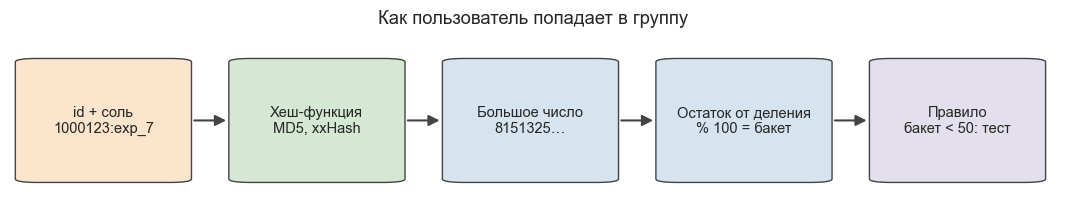

,Строка,Хеш (начало),Число,Бакет: число % 100,Группа
0,1000123,b394478f3dad…,12940046309882973613,13,тест
1,1000124,5438be33095c…,6068809624291378535,35,тест
2,1000125,a32e69c03c4f…,11758451951477428062,62,контроль
3,1000126,d1889a296bab…,15098487253450350021,21,тест


In [6]:
def rule_half(values) -> np.ndarray:
    return values % 100 < 50


def bucket_steps(ids, salt: str) -> pd.DataFrame:
    """Показывает путь пользователя от id до группы."""
    rows = []
    for i in ids:
        key = f'{salt}:{i}' if salt else str(i)
        digest = hashlib.md5(key.encode()).hexdigest()
        number = int(digest[:16], 16)
        rows.append({'Строка': key, 'Хеш (начало)': digest[:12] + '…', 'Число': number, 'Бакет: число % 100': number % 100,
                     'Группа': 'тест' if number % 100 < 50 else 'контроль'})
    return pd.DataFrame(rows)


fig, ax = plt.subplots(figsize=(13.5, 2.3))
chain = [('id + соль\n1000123:exp_7', '#FCE5CD'), ('Хеш-функция\nMD5, xxHash', '#D5E8D4'), ('Большое число\n8151325…', '#D6E4F0'),
         ('Остаток от деления\n% 100 = бакет', '#D6E4F0'), ('Правило\nбакет < 50: тест', '#E4DFEC')]
for i, (label, color) in enumerate(chain):
    draw_box(ax, i * 0.2, 0.15, 0.165, 0.7, label, color)
    if i:
        draw_arrow(ax, (i * 0.2 - 0.035, 0.5), (i * 0.2, 0.5))
ax.set_xlim(-0.005, 0.975)
ax.set_ylim(0, 1)
ax.axis('off')
ax.set_title('Как пользователь попадает в группу')
plt.show()
bucket_steps([1000123, 1000124, 1000125, 1000126], '')

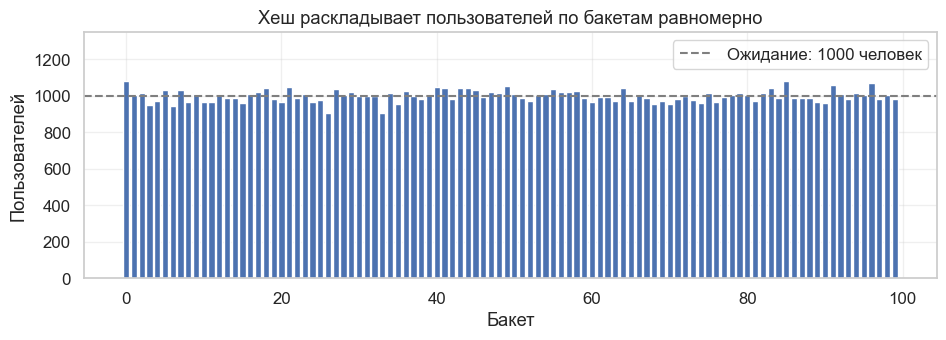

chi2 p-value равномерности: 0.329


In [7]:
buckets = (hash_ids(user_id, 'exp_7') % 100).astype(int)
counts_by_bucket = np.bincount(buckets, minlength=100)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(range(100), counts_by_bucket, color=BLUE, width=0.8)
ax.axhline(N_USERS / 100, color=GRAY, ls='--', label='Ожидание: 1000 человек')
ax.set_ylim(0, counts_by_bucket.max() * 1.25)
ax.set_xlabel('Бакет')
ax.set_ylabel('Пользователей')
ax.set_title('Хеш раскладывает пользователей по бакетам равномерно')
ax.legend(loc='upper right')
plt.show()
print(f'chi2 p-value равномерности: {stats.chisquare(counts_by_bucket).pvalue:.3f}')

Группа вычисляется в одну строчку, а бакеты получаются равномерными. Но есть проблема: у пользователя всего одно число, а значит, один бакет на все эксперименты. Если каждый новый тест берёт бакеты 0–49 как тест, то в него **всегда попадают одни и те же люди**.

**Соль** — это произвольная строка, которую приписывают к `id` перед хешированием. Обычно это название или идентификатор эксперимента: `hash("exp_1:1000123")`. Смена даже одного символа полностью меняет число, поэтому у каждого эксперимента получается своё независимое разбиение. Требование 3 выполнено, и по-прежнему ничего не надо хранить: достаточно знать `id` и соль.

Посмотрим на тех же пользователей в двух экспериментах. По нескольким строкам о независимости судить нельзя, поэтому выше считаем совпадение групп на всей базе: при независимости около половины.

In [8]:
sample_ids = [1000123, 1000124, 1000125, 1000126, 1000127, 1000128]
first_salt, second_salt = bucket_steps(sample_ids, 'exp_1'), bucket_steps(sample_ids, 'exp_2')
same_group = np.mean(rule_half(hash_ids(user_id, 'exp_1')) == rule_half(hash_ids(user_id, 'exp_2')))
print(f'Группы двух экспериментов совпали у {same_group:.1%} всех пользователей')
pd.DataFrame({'Пользователь': sample_ids, 'Бакет exp_1': first_salt['Бакет: число % 100'], 'Группа exp_1': first_salt['Группа'],
              'Бакет exp_2': second_salt['Бакет: число % 100'], 'Группа exp_2': second_salt['Группа']})

Группы двух экспериментов совпали у 50.1% всех пользователей


,Пользователь,Бакет exp_1,Группа exp_1,Бакет exp_2,Группа exp_2
0,1000123,20,тест,26,тест
1,1000124,10,тест,16,тест
2,1000125,89,контроль,96,контроль
3,1000126,0,тест,74,контроль
4,1000127,34,тест,92,контроль
5,1000128,71,контроль,1,тест


Почему без соли плохо, видно на примере. Пусть у прошлого теста остался небольшой эффект: пользователи варианта успели привыкнуть к изменению. Следующий тест — это A/A, разницы быть не должно.

In [9]:
hash_no_salt = hash_ids(user_id, '')
test_1 = hash_no_salt % 2 == 0
carryover = 0.05                                       # пользователи теста A «привыкли» к изменению
metric_after = metric + carryover * test_1

test_2_same = hash_no_salt % 2 == 0                    # следующий тест на том же хеше без соли
test_2_salt = hash_ids(user_id, 'exp_2') % 2 == 0      # следующий тест с собственной солью
rows = {}
for name, test in [('Без соли', test_2_same), ('Своя соль', test_2_salt)]:
    rows[name] = {'Совпадение с прошлым тестом': (test == test_1).mean(), 'Разница (A/A)': metric_after[test].mean() - metric_after[~test].mean(),
                  'p-value': stats.ttest_ind(metric_after[test], metric_after[~test]).pvalue}
pd.DataFrame(rows).T

,Совпадение с прошлым тестом,Разница (A/A),p-value
Без соли,1,0.06064,1.357e-20
Своя соль,0.499,0.006674,0.3059


Без соли следующий A/A показывает значимую разницу: в нём живёт эффект прошлого теста. С собственной солью группы совпадают только в половине случаев, как и должно быть.

Вторая задача: один поток трафика нужно поделить между экспериментами, а потом внутри каждого разделить тест и контроль. Если на обоих шагах взять одну соль, все пользователи `exp_1` окажутся в тесте, а все пользователи `exp_2` в контроле. Поэтому нужен **двойной посол**: одна соль решает, в какой эксперимент попал пользователь, другая внутри него выбирает вариант.

In [10]:
traffic = hash_ids(user_id, 'salt_1') % 2 == 0          # поток делит трафик между exp_1 и exp_2
same_salt = hash_ids(user_id, 'salt_1') % 2 == 0        # внутри потока та же соль
own_salt_1 = hash_ids(user_id, 'salt_2') % 2 == 0
own_salt_2 = hash_ids(user_id, 'salt_3') % 2 == 0
pd.DataFrame({
    'Одна соль на всё': {'exp_1: доля теста': same_salt[traffic].mean(), 'exp_2: доля теста': same_salt[~traffic].mean()},
    'Двойной посол': {'exp_1: доля теста': own_salt_1[traffic].mean(), 'exp_2: доля теста': own_salt_2[~traffic].mean()},
})

,Одна соль на всё,Двойной посол
exp_1: доля теста,1,0.5002
exp_2: доля теста,0,0.4985


## Качество хеша

Всё это работает только при «хорошем» хеше: при разных солях группы должны получаться независимыми. Но разные функции справляются с этим по-разному. Сравним четыре из них на 50 тысячах последовательных id: для пяти пар солей считаем связь между группами двух тестов и обычный SRM.

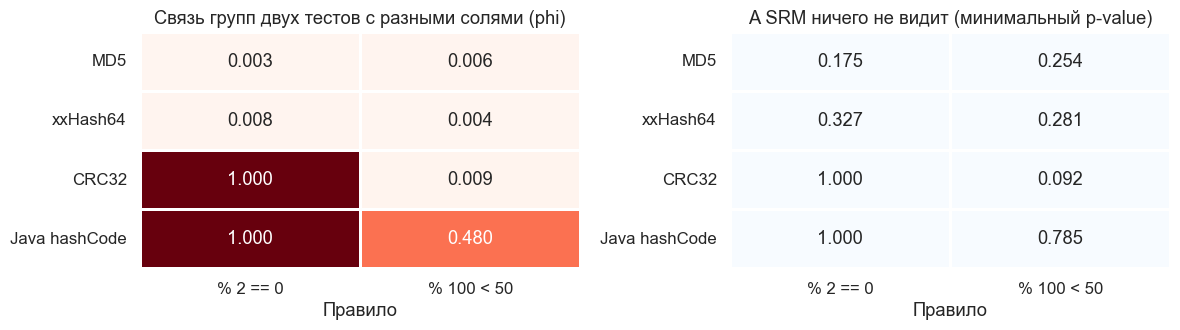

In [11]:
def java_hash(text: str) -> int:
    value = 0
    for char in text.encode():
        value = (31 * value + char) & 0xffffffff
    return value


HASHES = {'MD5': md5_int, 'xxHash64': lambda s: xxhash.xxh64_intdigest(s.encode()),
          'CRC32': lambda s: zlib.crc32(s.encode()), 'Java hashCode': java_hash}
RULES = {'% 2 == 0': lambda v: v % 2 == 0, '% 100 < 50': lambda v: v % 100 < 50}
SALT_PAIRS = [(f'exp_{k}a', f'exp_{k}b') for k in range(5)]
sequential = np.arange(1_000_000, 1_050_000)


def overlap_test(a, b) -> tuple:
    """Хи-квадрат для таблицы пересечения двух тестов: p-value и сила связи phi."""
    table = pd.crosstab(a, b).reindex(index=[False, True], columns=[False, True], fill_value=0).to_numpy()
    if (table.sum(axis=0) == 0).any() or (table.sum(axis=1) == 0).any():
        return 0.0, 1.0
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    return stats.chi2.sf(chi2, 1), float(np.sqrt(chi2 / table.sum()))


records = []
for hash_name, hash_fn in HASHES.items():
    hashed = [(hash_ids(sequential, s1, hash_fn), hash_ids(sequential, s2, hash_fn)) for s1, s2 in SALT_PAIRS]
    for rule_name, rule in RULES.items():
        checks = [overlap_test(rule(h1), rule(h2)) for h1, h2 in hashed]
        srm = [stats.binomtest(int(rule(h1).sum()), len(h1)).pvalue for h1, _ in hashed]
        records.append({'Хеш': hash_name, 'Правило': rule_name, 'phi': max(c[1] for c in checks), 'min p SRM': min(srm)})
hash_table = pd.DataFrame(records)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
phi_map = hash_table.pivot(index='Хеш', columns='Правило', values='phi').reindex(index=list(HASHES), columns=list(RULES))
srm_map = hash_table.pivot(index='Хеш', columns='Правило', values='min p SRM').reindex(index=list(HASHES), columns=list(RULES))
sns.heatmap(phi_map, annot=True, fmt='.3f', cmap='Reds', vmin=0, vmax=1, ax=axes[0], cbar=False, linewidths=1)
axes[0].set_title('Связь групп двух тестов с разными солями (phi)')
axes[0].set_ylabel('')
sns.heatmap(srm_map, annot=True, fmt='.3f', cmap='Blues_r', vmin=0, vmax=0.05, ax=axes[1], cbar=False, linewidths=1)
axes[1].set_title('А SRM ничего не видит (минимальный p-value)')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

Слева связь групп при **разных солях**: 0 значит независимость, 1 значит, что группы полностью определяют друг друга. Справа SRM для тех же случаев.

* **MD5 и xxHash** работают при обоих правилах.
* **CRC32 и Java `hashCode` при `% 2`** дают полную связь: соль не работает, группы двух тестов совпадают или противоположны. Причина в том, что у этих функций младший бит зависит от входа линейно.
* **Зависит от правила.** При `% 100` CRC32 уже чист, а Java `hashCode` остаётся связанным. Значит, оценивать надо сочетание хеша, правила и формата id, а не хеш сам по себе.
* **SRM этого не видит:** доли групп идеальные, хотя тесты идут на одних и тех же людях.

Kohavi и соавторы в 2009 году проверяли хеши так же и пришли к тому же выводу: многие популярные функции не прошли даже парный тест.

Вторая проверка — много A/A с разными солями: если сплит случаен, p-value равномерны.

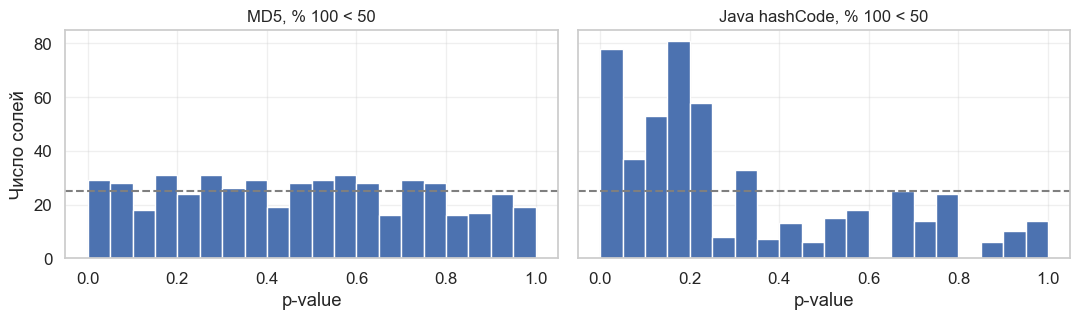

,Доля значимых,Разброс доли группы,Ожидаемый разброс
"MD5, % 100 < 50",0.058,0.007401,0.007071
"Java hashCode, % 100 < 50",0.156,0.00198,0.007071


In [12]:
def aa_pvalues(hash_fn, rule, ids, values, reps: int = 500) -> tuple:
    """A/A на множестве солей: p-value теста Уэлча и доля группы."""
    pvalues, shares = np.zeros(reps), np.zeros(reps)
    for k in range(reps):
        test = rule(hash_ids(ids, f'aa_{k}', hash_fn))
        pvalues[k] = stats.ttest_ind(values[test], values[~test], equal_var=False).pvalue
        shares[k] = test.mean()
    return pvalues, shares


aa_ids, aa_metric = user_id[:5000], metric[:5000]
aa_cases = {'MD5, % 100 < 50': (md5_int, RULES['% 100 < 50']), 'Java hashCode, % 100 < 50': (java_hash, RULES['% 100 < 50'])}
aa_results = {name: aa_pvalues(fn, rule, aa_ids, aa_metric) for name, (fn, rule) in aa_cases.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
summary = {}
for ax, (name, (pvalues, shares)) in zip(axes, aa_results.items()):
    ax.hist(pvalues, bins=20, range=(0, 1), color=BLUE)
    ax.axhline(len(pvalues) / 20, color=GRAY, ls='--')
    ax.set_xlabel('p-value')
    ax.set_title(name, fontsize=12)
    summary[name] = {'Доля значимых': (pvalues < ALPHA).mean(), 'Разброс доли группы': shares.std(), 'Ожидаемый разброс': 0.5 / np.sqrt(len(aa_ids))}
axes[0].set_ylabel('Число солей')
plt.tight_layout()
plt.show()
pd.DataFrame(summary).T

Слева MD5: равномерные p-value, 5.8% значимых. Справа Java `hashCode`: 15.6% ложных срабатываний, хотя разброс доли группы даже меньше ожидаемого (0.002 против 0.007). Подозрительно ровные группы — такой же сигнал поломки, как и перекошенные.

Скорость при выборе обычно вторична: разница между функциями измеряется долями микросекунды. Важнее, чтобы хеш считался одинаково там, где группу назначают, и там, где её пересчитывают аналитики, например в Go-сервисе и в ClickHouse.

## Параллельность тестов

Теперь у нас есть надёжное назначение групп. Осталось решить, как уместить много тестов на одном трафике. Варианта три.

* **Изоляция.** Каждый пользователь попадает максимум в один тест. Чисто, но трафик быстро заканчивается.
* **Слои.** Статья Google 2010 года предлагает делить не только трафик, но и параметры системы. **Слой** — это набор параметров, которые нельзя менять независимо, например цвет фона и цвет текста. Внутри слоя тесты изолированы, а между слоями пересекаются: в каждом слое своё разбиение `f(cookie, layer) % 1000`. **Домен** — это срез трафика, в котором может быть своя структура слоёв. Часть трафика можно отвести под тесты, меняющие сразу многое. Отдельные **launch layers** нужны для постепенной раскатки.
* **Полное пересечение.** Каждый тест получает своё независимое разбиение. Так работает LinkedIn: по умолчанию пользователь участвует во всех подходящих тестах, а уникальный `hashID` делает разбиения ортогональными. Для случаев, где тесты точно мешают друг другу, используется `gating key`: второй тест включается только внутри определённой группы первого.

Варианты можно совмещать: на схеме справа гибрид, где часть трафика изолирована, а остальное разбито на слои.

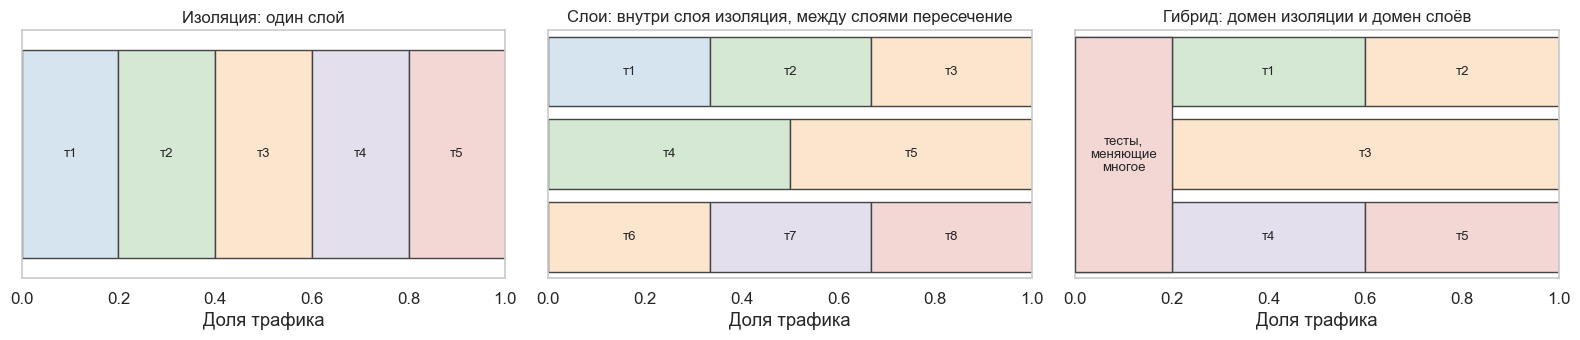

In [13]:
def plot_layers(ax, title, rows, note=None):
    colors = ['#D6E4F0', '#D5E8D4', '#FCE5CD', '#E4DFEC', '#F2D7D5']
    for level, row in enumerate(rows):
        y = len(rows) - 1 - level
        x = 0
        for k, (share, label) in enumerate(row):
            ax.add_patch(Rectangle((x, y + 0.08), share, 0.84, fc=colors[(k + level) % 5], ec='#444444', lw=1))
            ax.text(x + share / 2, y + 0.5, label, ha='center', va='center', fontsize=9.5)
            x += share
    ax.set_xlim(0, 1)
    ax.set_ylim(0, len(rows))
    ax.set_xlabel('Доля трафика')
    ax.set_yticks([])
    ax.grid(False)
    ax.set_title(title, fontsize=12)


fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
plot_layers(axes[0], 'Изоляция: один слой', [[(0.2, f'т{i}') for i in range(1, 6)]])
plot_layers(axes[1], 'Слои: внутри слоя изоляция, между слоями пересечение',
            [[(1 / 3, 'т1'), (1 / 3, 'т2'), (1 / 3, 'т3')], [(0.5, 'т4'), (0.5, 'т5')], [(1 / 3, 'т6'), (1 / 3, 'т7'), (1 / 3, 'т8')]])
plot_layers(axes[2], 'Гибрид: домен изоляции и домен слоёв', [[(0.2, ''), (0.4, 'т1'), (0.4, 'т2')], [(0.2, ''), (0.8, 'т3')], [(0.2, ''), (0.4, 'т4'), (0.4, 'т5')]])
axes[2].add_patch(Rectangle((0, 0.08), 0.2, 2.84, fc='#F2D7D5', ec='#444444', lw=1, zorder=3))
axes[2].text(0.1, 1.5, 'тесты,\nменяющие\nмногое', ha='center', va='center', fontsize=9.5, zorder=4)
plt.tight_layout()
plt.show()

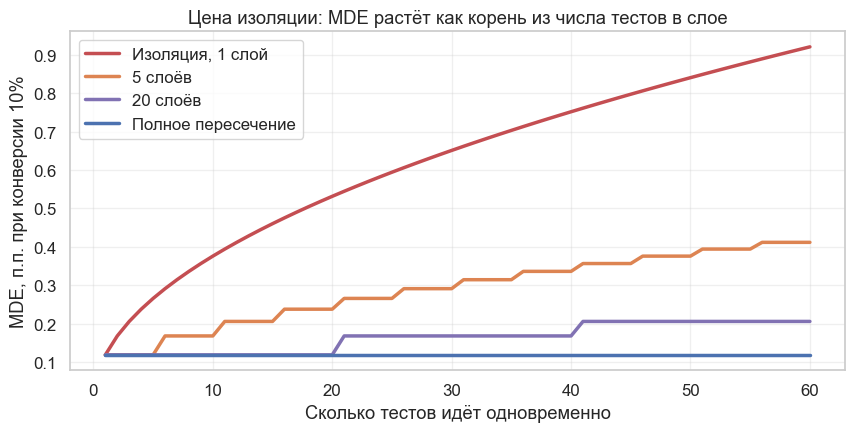

,"Изоляция, 1 слой",5 слоёв,20 слоёв,Полное пересечение
1 тест,0.119,0.119,0.119,0.119
20 тестов,0.532,0.238,0.119,0.119
60 тестов,0.921,0.412,0.206,0.119


In [14]:
def mde(users: float, base: float = 0.10, power: float = 0.8) -> float:
    """Абсолютный MDE для конверсии, когда весь тест получает users пользователей, сплит 50/50."""
    return (Z + stats.norm.ppf(power)) * np.sqrt(2 * base * (1 - base) / (users / 2))


TRAFFIC = 2_000_000
counts = np.arange(1, 61)
layer_options = {'Изоляция, 1 слой': 1, '5 слоёв': 5, '20 слоёв': 20, 'Полное пересечение': 10 ** 9}
fig, ax = plt.subplots(figsize=(10, 4.4))
for (name, layers), color in zip(layer_options.items(), [RED, ORANGE, PURPLE, BLUE]):
    shares = np.ceil(counts / layers)
    ax.plot(counts, mde(TRAFFIC / shares) * 100, color=color, lw=2.5, label=name)
ax.set_xlabel('Сколько тестов идёт одновременно')
ax.set_ylabel('MDE, п.п. при конверсии 10%')
ax.set_title('Цена изоляции: MDE растёт как корень из числа тестов в слое')
ax.legend()
plt.show()
table = pd.DataFrame({name: [mde(TRAFFIC / np.ceil(k / layers)) * 100 for k in (1, 20, 60)] for name, layers in layer_options.items()},
                     index=['1 тест', '20 тестов', '60 тестов'])
table.round(3)

Считаем MDE при 2 млн пользователей и конверсии 10%. При изоляции 60 тестов делят трафик, и MDE вырастает с 0.12 до 0.92 п.п., то есть почти в 8 раз. Слои и пересечение возвращают чувствительность: в 20 слоях те же 60 тестов дают 0.21 п.п. Формула простая: MDE растёт как $\sqrt{k}$, где $k$ — число тестов, делящих трафик внутри слоя.

Цена слоёв и пересечения — возможное влияние тестов друг на друга. Насколько она реальна, разберём в следующем разделе.

**Остаточный эффект.** У разделения пользователей на постоянные бакеты есть своя ловушка. Если следующий тест получает те же бакеты, что прошлый, эффект прошлого теста попадает в него. В расчёте ниже прошлый тест оставил след в 0.03 стандартного отклонения, затухающий за две недели, а в группе 200 тысяч человек. Параметры условные, важна форма кривой.

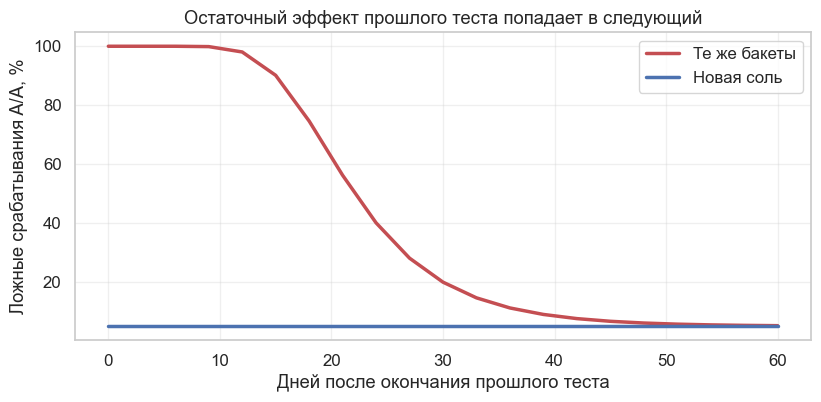

,Те же бакеты,Новая соль
0,1,0.05
15,0.901,0.05
30,0.2,0.05
60,0.052,0.05


In [15]:
def reuse_fpr(lags, effect: float = 0.03, decay_days: float = 14, n_group: int = 200_000, sd: float = 1.0) -> pd.DataFrame:
    """Вероятность ложного срабатывания A/A сразу после теста на тех же бакетах и с новой солью."""
    se = sd * np.sqrt(2 / n_group)
    shift = effect * np.exp(-np.asarray(lags) / decay_days) / se
    power = stats.norm.sf(Z - shift) + stats.norm.cdf(-Z - shift)
    return pd.DataFrame({'Те же бакеты': power, 'Новая соль': np.full(len(power), ALPHA)}, index=lags)


lags = np.arange(0, 61, 3)
reuse = reuse_fpr(lags)
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(reuse.index, reuse['Те же бакеты'] * 100, color=RED, lw=2.5, label='Те же бакеты')
ax.plot(reuse.index, reuse['Новая соль'] * 100, color=BLUE, lw=2.5, label='Новая соль')
ax.set_xlabel('Дней после окончания прошлого теста')
ax.set_ylabel('Ложные срабатывания A/A, %')
ax.set_title('Остаточный эффект прошлого теста попадает в следующий')
ax.legend()
plt.show()
reuse.loc[[0, 15, 30, 60]].round(3)

Сразу после теста A/A на тех же бакетах почти всегда значим, через 30 дней ложных срабатываний всё ещё 20%. Новая соль убирает проблему полностью. Spotify обсуждает это прямо: в 2020 году они описывали «соляную машину», которая перемешивает освободившихся пользователей с новой солью. Перемешанная часть меньше всего трафика, поэтому нужен компенсирующий множитель, и при значении выше 5 новые тесты не запускали. В 2021 году они перешли на один миллион постоянных бакетов и одну соль: выборка берётся на уровне бакетов, а внутри них пользователи назначаются в варианты случайно. Их анализ показывает, что обычные t-тесты остаются корректны, но у эксклюзивных программ возможно смещение от истории последних дней перед тестом.

## Пересечения тестов

Для двух тестов возникают два разных вопроса, и их часто путают.

* **Ортогональность:** независимо ли пользователи попадают в группы двух тестов? Это свойство **сплита**, оно проверяется без метрик.
* **Аддитивность:** складываются ли эффекты, или эффект одного теста зависит от группы в другом? Это свойство **продукта**, оно проверяется по метрикам.

Сначала проверяем первое, потому что без него второе не имеет смысла: если тесты неортогональны, увидеть работу вариантов отдельно и вместе нельзя.

### Ортогональность

Строим **матрицу пересечения** 2×2: сколько пользователей попало в каждую пару групп двух тестов. При независимости и сплите 50/50 в каждой клетке будет 25%. К матрице применяем χ²: та же проверка, что SRM, только для двух экспериментов. Сила связи выражается через $\phi = \sqrt{\chi^2 / n}$.

In [16]:
pair = user_id[:50_000]
md5_a, md5_b = hash_ids(pair, 'exp_a'), hash_ids(pair, 'exp_b')
rule = RULES['% 100 < 50']
cases = {
    'MD5, разные соли': (rule(md5_a), rule(md5_b)),
    'MD5, одна соль': (rule(md5_a), rule(md5_a)),
    'MD5, соль одна, бакеты 0–49 и 25–74': (md5_a % 100 < 50, (md5_a % 100 >= 25) & (md5_a % 100 < 75)),
    'Java hashCode, разные соли': (rule(hash_ids(pair, 'exp_a', java_hash)), rule(hash_ids(pair, 'exp_b', java_hash))),
}
rows = {}
for name, (a, b) in cases.items():
    p_value, phi = overlap_test(a, b)
    rows[name] = {'Доля теста A': a.mean(), 'Доля теста B': b.mean(), 'A и B вместе': (a & b).mean(),
                  'Ожидание при независимости': a.mean() * b.mean(), 'p-value': p_value, 'phi': phi}
pd.DataFrame(rows).T

,Доля теста A,Доля теста B,A и B вместе,Ожидание при независимости,p-value,phi
"MD5, разные соли",0.4975,0.5014,0.2488,0.2495,0.5691,0.002546
"MD5, одна соль",0.4975,0.4975,0.4975,0.2475,0,1
"MD5, соль одна, бакеты 0–49 и 25–74",0.4975,0.5,0.2505,0.2488,0.1261,0.00684
"Java hashCode, разные соли",0.5001,0.5003,0.1302,0.2502,0,0.48


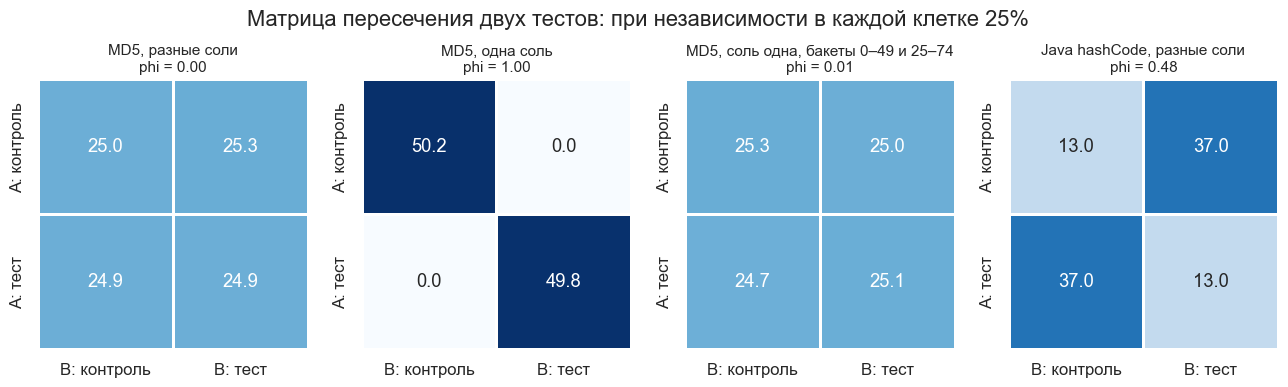

In [17]:
def share_matrix(a, b) -> pd.DataFrame:
    """Матрица пересечения: доля пользователей в каждой паре групп, %."""
    table = pd.crosstab(pd.Series(a, name='A'), pd.Series(b, name='B'), normalize='all')
    return table.reindex(index=[False, True], columns=[False, True], fill_value=0) * 100


fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (name, (a, b)) in zip(axes, cases.items()):
    sns.heatmap(share_matrix(a, b), annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=50, cbar=False, linewidths=1, ax=ax,
                xticklabels=['B: контроль', 'B: тест'], yticklabels=['A: контроль', 'A: тест'])
    ax.set_title(f'{name}\nphi = {overlap_test(a, b)[1]:.2f}', fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('')
fig.suptitle('Матрица пересечения двух тестов: при независимости в каждой клетке 25%', y=1.08)
plt.show()

* **Разные соли:** во всех клетках по 25%, $\phi$ около нуля.
* **Одна соль:** диагональная матрица, тесты полностью совпадают.
* **Java `hashCode`:** клетки перекошены, $\phi = 0.48$, хотя доли групп нормальные: суммы по строкам и столбцам те же 50%.
* **Третья матрица важнее всего.** Одна соль, бакеты 0–49 и 25–74. В клетках ровно по 25%, и χ² ничего не находит ($p = 0.13$). Но разбиение не случайно: группы жёстко заданы одними и теми же бакетами. **Проверка видит только матрицу 2×2**, поэтому при фиксированных бакетах она не заменяет разных солей.

Проверка дешёвая: ей нужны только назначения, а не метрики. Vermeer описывает такую схему в Vista: сначала пересечение трафика, затем метрики.

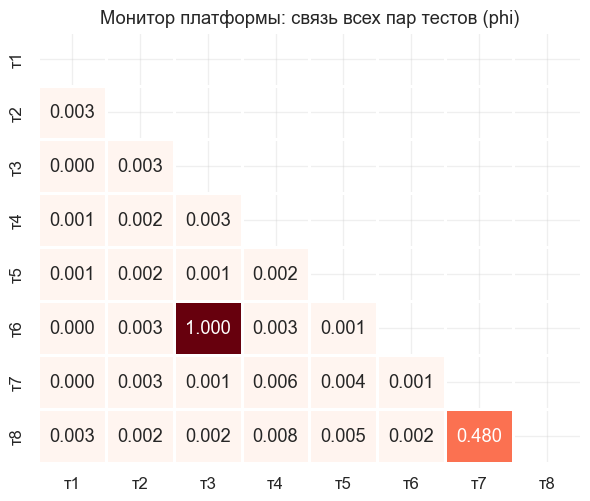

Пар: 28, сигнал с поправкой Бонферрони: [('т3', 'т6'), ('т7', 'т8')]


In [18]:
matrix_ids = user_id
names = [f'т{i}' for i in range(1, 9)]
groups_by_test = {name: rule(hash_ids(matrix_ids, f'test_{k}')) for k, name in enumerate(names)}
groups_by_test['т6'] = rule(hash_ids(matrix_ids, 'test_2'))                        # ошибка: у т6 соль теста т3
groups_by_test['т7'] = rule(hash_ids(matrix_ids, 'exp_a', java_hash))              # т7 и т8 назначены слабым хешем
groups_by_test['т8'] = rule(hash_ids(matrix_ids, 'exp_b', java_hash))

phi_matrix, p_matrix = pd.DataFrame(0.0, names, names), pd.DataFrame(1.0, names, names)
for i, first in enumerate(names):
    for second in names[i + 1:]:
        p_value, phi = overlap_test(groups_by_test[first], groups_by_test[second])
        phi_matrix.loc[first, second], phi_matrix.loc[second, first] = phi, phi
        p_matrix.loc[first, second], p_matrix.loc[second, first] = p_value, p_value

fig, ax = plt.subplots(figsize=(7, 5.6))
mask = np.triu(np.ones((8, 8), dtype=bool))
sns.heatmap(phi_matrix, mask=mask, annot=True, fmt='.3f', cmap='Reds', vmin=0, vmax=1, cbar=False, linewidths=1, ax=ax)
ax.set_title('Монитор платформы: связь всех пар тестов (phi)')
plt.show()
n_pairs = len(names) * (len(names) - 1) // 2
flagged = [(a, b) for i, a in enumerate(names) for b in names[i + 1:] if p_matrix.loc[a, b] < ALPHA / n_pairs]
print(f'Пар: {n_pairs}, сигнал с поправкой Бонферрони: {flagged}')

На платформе проверку удобно смотреть как **матрицу всех пар тестов**. Здесь восемь тестов, и в данных спрятаны две поломки: у т6 по ошибке соль теста т3, а т7 и т8 назначены слабым хешем. Обе пары сразу выделяются, остальные клетки около нуля. Клеток много, поэтому порог берём с поправкой на число пар.

**Что будет, если эту проверку пропустить?** Часто говорят, что неортогональность создаёт ложную неаддитивность. Проверим. Тест A не делает ничего, тест B даёт настоящий эффект +0.20, взаимодействия нет.

In [19]:
def simulate_pair(a, b, effect_a, effect_b, interaction, seed=1):
    """Метрика пользователя с той же структурой по id, что и раньше."""
    local = np.random.default_rng(seed)
    size = len(a)
    base = 1 + 0.6 * tenure[:size] + 0.3 * ios[:size] + local.normal(0, 1, size)
    return base + effect_a * a + effect_b * b + interaction * (a & b)


java_a, java_b = rule(hash_ids(pair, 'exp_a', java_hash)), rule(hash_ids(pair, 'exp_b', java_hash))
effect_b = 0.20
rows = {}
for name, (a, b) in {'Разные соли, MD5': (rule(md5_a), rule(md5_b)), 'Java hashCode': (java_a, java_b)}.items():
    y = simulate_pair(a, b, 0.0, effect_b, 0.0)
    frame = pd.DataFrame({'y': y, 'a': a.astype(int), 'b': b.astype(int)})
    fit = smf.ols('y ~ a * b', frame).fit()
    rows[name] = {'phi': overlap_test(a, b)[1], 'Наивный эффект A': y[a].mean() - y[~a].mean(), 'p-value наивного': stats.ttest_ind(y[a], y[~a]).pvalue,
                  'A с учётом B': fit.params['a'], 'Взаимодействие': fit.params['a:b'], 'p-value взаимодействия': fit.pvalues['a:b']}
pd.DataFrame(rows).T

,phi,Наивный эффект A,p-value наивного,A с учётом B,Взаимодействие,p-value взаимодействия
"Разные соли, MD5",0.002546,0.001672,0.8539,0.003083,-0.001829,0.9194
Java hashCode,0.48,-0.09284,1.488e-24,-0.001977,0.00749,0.7163


In [20]:
def many_salts(hash_fn, reps: int = 200, size: int = 10_000, effect: float = 0.20) -> dict:
    """Настоящий эффект только у B: как часто появляются ложный эффект A и ложное взаимодействие."""
    local = np.random.default_rng(2)
    ids, false_main, false_interaction, links = user_id[:size], 0, 0, []
    for k in range(reps):
        a, b = rule(hash_ids(ids, f'a{k}', hash_fn)), rule(hash_ids(ids, f'bb{k}', hash_fn))
        y = 1 + 0.6 * tenure[:size] + 0.3 * ios[:size] + local.normal(0, 1, size) + effect * b
        false_main += stats.ttest_ind(y[a], y[~a]).pvalue < ALPHA
        false_interaction += interaction_test(y[a & b], y[a & ~b], y[~a & b], y[~a & ~b])['p-value'] < ALPHA
        links.append(abs(np.corrcoef(a, b)[0, 1]))
    return {'Средний |phi|': np.mean(links), 'Ложный эффект A': false_main / reps, 'Ложное взаимодействие': false_interaction / reps}


def interaction_test(y1_1, y1_0, y0_1, y0_0) -> dict:
    """Проверка аддитивности по четырём группам, аргументы — массивы метрики."""
    groups = [y1_1, y1_0, y0_1, y0_0]
    delta = (y1_1.mean() - y0_1.mean()) - (y1_0.mean() - y0_0.mean())
    se = np.sqrt(sum(g.var(ddof=1) / len(g) for g in groups))
    return {'Эффект A при B=1': y1_1.mean() - y0_1.mean(), 'Эффект A при B=0': y1_0.mean() - y0_0.mean(), 'Δ': delta, 'SE': se,
            'z': delta / se, 'p-value': 2 * stats.norm.sf(abs(delta / se))}


pd.DataFrame({'MD5': many_salts(md5_int), 'Java hashCode': many_salts(java_hash)}).T

,Средний |phi|,Ложный эффект A,Ложное взаимодействие
MD5,0.008228,0.075,0.07
Java hashCode,0.632,0.98,0.055


Наивный эффект A при Java `hashCode` равен −0.09 ($p \approx 10^{-24}$), хотя A не делает ничего. Это эффект B, который протёк через связь групп: $\phi \cdot 0.20$ со знаком связи. Команда A увидит значимый вред и закроет тест, причём SRM будет чистым.

А вот **ложного взаимодействия** здесь нет: $p = 0.72$. Одна соль ничего не доказывает, поэтому во второй таблице повторяем расчёт на 200 солях. У Java `hashCode` ложный эффект A появляется почти всегда, а ложное взаимодействие не чаще, чем у MD5. Причина в том, что каждая из четырёх ячеек остаётся честной оценкой своей комбинации, а портится только сравнение, которое усредняет ячейки с неравными весами. Регрессия с обоими тестами возвращает истинный ноль.

Значит, опасность неортогональности в загрязнении главного эффекта, а не в ложной неаддитивности. Если же ячейка пуста, как при $\phi = 1$, оценить взаимодействие нельзя вообще. Этот вывод относится к нашей модели, где истинные эффекты аддитивны, а структура id общая для всех. В других моделях сплита он может быть иным, поэтому проверяйте свой случай.

### Аддитивность

Ортогональные тесты дают матрицу из четырёх групп. Если эффекты складываются, клетка «оба теста» равна сумме эффектов, а эффект A одинаков в обеих группах B. Мера нарушения:

$$
\Delta = (\bar{Y}_{11} - \bar{Y}_{01}) - (\bar{Y}_{10} - \bar{Y}_{00}), \qquad
SE(\Delta) = \sqrt{\sum_{i,j} \frac{\sigma^2_{ij}}{n_{ij}}}
$$

Здесь первый индекс — группа в A, второй — в B. То же самое даёт регрессия `y ~ a * b`: коэффициент при `a:b` равен $\Delta$. Microsoft использует χ²-тест разницы двух эффектов, но по смыслу это та же проверка.

Смоделируем пару тестов: каждый даёт +0.05, а вместе они мешают друг другу на −0.08.

{'Эффект A при B=1': np.float64(-0.0294), 'Эффект A при B=0': np.float64(0.0628), 'Δ': np.float64(-0.0922), 'SE': np.float64(0.0129), 'z': np.float64(-7.1712), 'p-value': np.float64(0.0)}
Регрессия: коэффициент a:b = -0.0922, ошибка 0.0129, p = 0.00000


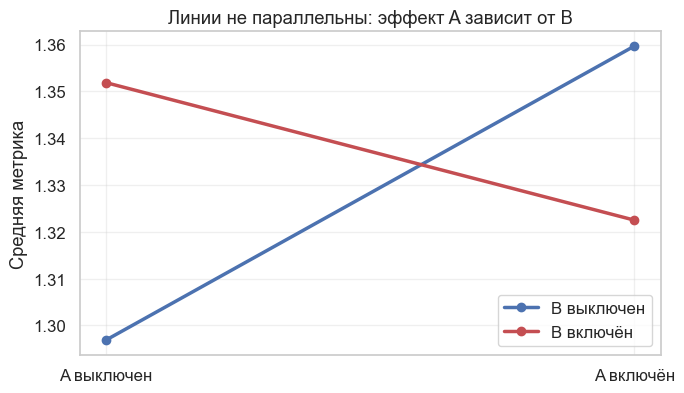

In [21]:
hash_a, hash_b = rule(hash_ids(user_id, 'exp_a')), rule(hash_ids(user_id, 'exp_b'))
y_true = 1 + 0.6 * tenure + rng.normal(0, 1, N_USERS) + 0.05 * hash_a + 0.05 * hash_b - 0.08 * (hash_a & hash_b)
manual = interaction_test(y_true[hash_a & hash_b], y_true[hash_a & ~hash_b], y_true[~hash_a & hash_b], y_true[~hash_a & ~hash_b])
frame = pd.DataFrame({'y': y_true, 'a': hash_a.astype(int), 'b': hash_b.astype(int)})
regression = smf.ols('y ~ a * b', frame).fit()
print({k: round(v, 4) for k, v in manual.items()})
print(f"Регрессия: коэффициент a:b = {regression.params['a:b']:.4f}, ошибка {regression.bse['a:b']:.4f}, p = {regression.pvalues['a:b']:.5f}")

means = frame.groupby(['b', 'a'])['y'].mean().unstack()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(['A выключен', 'A включён'], means.loc[0], marker='o', color=BLUE, lw=2.5, label='B выключен')
ax.plot(['A выключен', 'A включён'], means.loc[1], marker='o', color=RED, lw=2.5, label='B включён')
ax.set_ylabel('Средняя метрика')
ax.set_title('Линии не параллельны: эффект A зависит от B')
ax.legend()
plt.show()

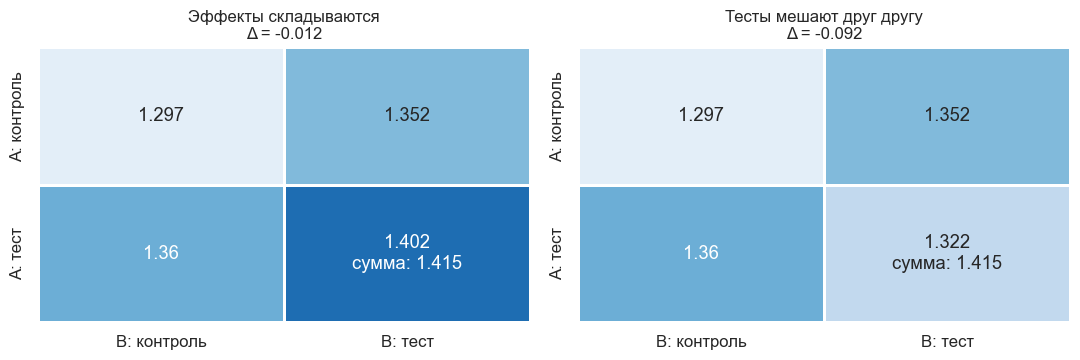

In [22]:
def effect_matrix(ax, y, a, b, title):
    """Матрица средних по четырём группам и сравнение клетки «оба» с суммой эффектов."""
    means = pd.DataFrame({'y': y, 'a': a, 'b': b}).groupby(['a', 'b'])['y'].mean().unstack()
    additive = means.loc[True, False] + means.loc[False, True] - means.loc[False, False]
    labels = means.round(3).astype(str).to_numpy()
    labels[1, 1] = f'{means.loc[True, True]:.3f}\nсумма: {additive:.3f}'
    sns.heatmap(means, annot=labels, fmt='', cmap='Blues', vmin=1.28, vmax=1.44, cbar=False, linewidths=1, ax=ax, xticklabels=['B: контроль', 'B: тест'], yticklabels=['A: контроль', 'A: тест'])
    ax.set_title(f'{title}\nΔ = {means.loc[True, True] - additive:+.3f}', fontsize=12)
    ax.set_xlabel('')
    ax.set_ylabel('')


fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
effect_matrix(axes[0], y_true + 0.08 * (hash_a & hash_b), hash_a, hash_b, 'Эффекты складываются')
effect_matrix(axes[1], y_true, hash_a, hash_b, 'Тесты мешают друг другу')
plt.tight_layout()
plt.show()

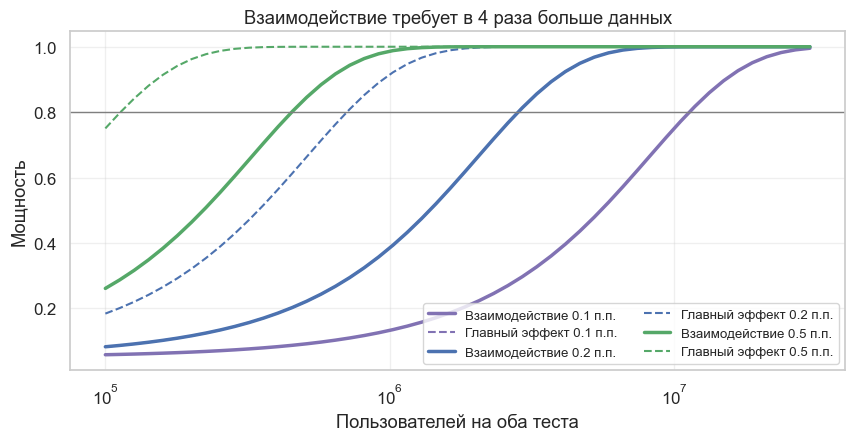

,Симуляция 0.2 п.п.,0.1 п.п.,0.2 п.п.,0.5 п.п.
400 тысяч,0.182,0.082,0.184,0.75
1.6 млн,0.557,0.184,0.559,1
6.4 млн,0.987,0.559,0.988,1


In [23]:
def interaction_power(users, delta, base=0.10):
    """Мощность теста на взаимодействие и главного эффекта того же размера при равных четырёх группах."""
    se_main = np.sqrt(4 * base * (1 - base) / users)
    return (stats.norm.sf(Z - delta / (2 * se_main)) + stats.norm.cdf(-Z - delta / (2 * se_main)),
            stats.norm.sf(Z - delta / se_main) + stats.norm.cdf(-Z - delta / se_main))


def simulated_power(users, delta, base=0.10, reps=20_000):
    cell = users // 4
    local = np.random.default_rng(7)
    rates = np.array([base, base, base, base + delta])
    observed = local.binomial(cell, rates, (reps, 4)) / cell
    estimate = observed[:, 3] - observed[:, 2] - observed[:, 1] + observed[:, 0]
    se = np.sqrt((observed * (1 - observed) / cell).sum(axis=1))
    return np.mean(np.abs(estimate / se) > Z)


users_grid = np.geomspace(1e5, 3e7, 50)
delta_grid = {'0.1 п.п.': 0.001, '0.2 п.п.': 0.002, '0.5 п.п.': 0.005}
fig, ax = plt.subplots(figsize=(10, 4.4))
for (name, delta), color in zip(delta_grid.items(), [PURPLE, BLUE, GREEN]):
    interaction, main = interaction_power(users_grid, delta)
    ax.plot(users_grid, interaction, color=color, lw=2.5, label=f'Взаимодействие {name}')
    ax.plot(users_grid, main, color=color, lw=1.5, ls='--', label=f'Главный эффект {name}')
ax.axhline(0.8, color=GRAY, lw=1)
ax.set_xscale('log')
ax.set_xlabel('Пользователей на оба теста')
ax.set_ylabel('Мощность')
ax.set_title('Взаимодействие требует в 4 раза больше данных')
ax.legend(fontsize=9.5, ncol=2)
plt.show()

needed = pd.DataFrame({name: [interaction_power(n, delta)[0] for n in (400_000, 1_600_000, 6_400_000)] for name, delta in delta_grid.items()},
                      index=['400 тысяч', '1.6 млн', '6.4 млн'])
needed.insert(0, 'Симуляция 0.2 п.п.', [simulated_power(n, 0.002) for n in (400_000, 1_600_000, 6_400_000)])
needed.round(3)

В матрице видно то же самое: при конфликте клетка «оба теста» заметно ниже суммы эффектов. В левой матрице Δ = −0.012 при ошибке 0.013, то есть это шум. Метод работает: на 100 тысячах пользователей мы получили $\Delta = -0.092$ при истинном −0.08, регрессия дала то же число. Но обратите внимание на стоимость.

$SE(\Delta)$ вдвое больше ошибки главного эффекта, потому что в формуле сразу четыре группы, каждая вчетверо меньше всей выборки. Значит, чтобы найти взаимодействие того же размера, что и главный эффект, **нужно в 4 раза больше данных**. Симуляция совпадает с формулой: при 1.6 млн пользователей главный эффект 0.2 п.п. находится почти всегда, а взаимодействие того же размера в 56% случаев. Для 99% нужно 6.4 млн.

А если взаимодействие меньше главного эффекта, что обычно и бывает, данных надо ещё больше. Отсюда вывод: **тест, не нашедший взаимодействия, не доказывает аддитивность.** Обычно у него просто нет мощности, и Microsoft прямо указывает на это ограничение в своём исследовании.

Вторая тонкость: **аддитивность зависит от шкалы.**

In [24]:
base_rate, lift_a, lift_b = 0.10, 1.10, 1.10
cells = pd.DataFrame({'Без тестов': [base_rate], 'Только A': [base_rate * lift_a], 'Только B': [base_rate * lift_b], 'A и B': [base_rate * lift_a * lift_b]}, index=['Конверсия'])
absolute = cells['A и B'].iloc[0] - cells['Только B'].iloc[0] - cells['Только A'].iloc[0] + cells['Без тестов'].iloc[0]
relative = np.log(cells['A и B'].iloc[0]) - np.log(cells['Только B'].iloc[0]) - np.log(cells['Только A'].iloc[0]) + np.log(cells['Без тестов'].iloc[0])
print(f'Δ в абсолютной шкале: {absolute * 100:+.2f} п.п., Δ в логарифмах: {relative:+.4f}')
cells.round(4)

Δ в абсолютной шкале: +0.10 п.п., Δ в логарифмах: +0.0000


,Без тестов,Только A,Только B,A и B
Конверсия,0.1,0.11,0.11,0.121


Оба теста поднимают конверсию на 10%. В относительной шкале эффекты складываются идеально, а в абсолютной появляется взаимодействие +0.10 п.п. Поэтому нужно заранее решить, в какой шкале вы понимаете аддитивность, и считать в ней.

### Проверять все пары?

Проверку одной пары можно повторить для всех и собрать матрицу, как для ортогональности. Здесь шесть чистых тестов. У пары т1 и т2 настоящий конфликт −0.10, у пары т4 и т5 слабое положительное взаимодействие +0.04, остальные эффекты складываются.

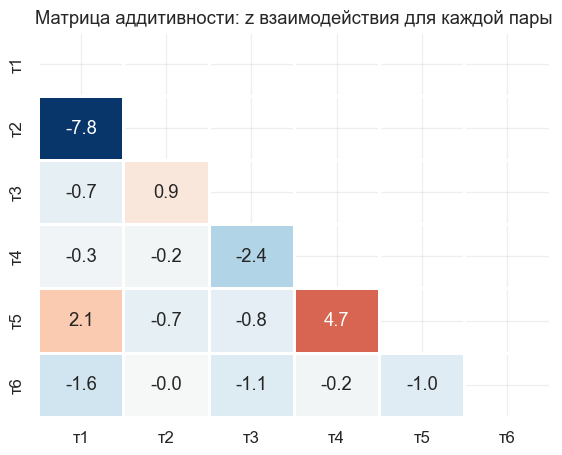

In [25]:
six = ['т1', 'т2', 'т3', 'т4', 'т5', 'т6']
assignment = {name: rule(hash_ids(user_id, f'clean_{k}')) for k, name in enumerate(six)}
local = np.random.default_rng(8)
y_pairs = 1 + 0.6 * tenure + local.normal(0, 1, N_USERS) + sum(0.03 * group for group in assignment.values())
y_pairs = y_pairs - 0.10 * (assignment['т1'] & assignment['т2']) + 0.04 * (assignment['т4'] & assignment['т5'])

z_matrix = pd.DataFrame(0.0, six, six)
for i, first in enumerate(six):
    for second in six[i + 1:]:
        a, b = assignment[first], assignment[second]
        z = interaction_test(y_pairs[a & b], y_pairs[a & ~b], y_pairs[~a & b], y_pairs[~a & ~b])['z']
        z_matrix.loc[first, second], z_matrix.loc[second, first] = z, z

fig, ax = plt.subplots(figsize=(6.6, 5))
sns.heatmap(z_matrix, mask=np.triu(np.ones((6, 6), dtype=bool)), annot=True, fmt='.1f', cmap='RdBu_r', center=0, vmin=-8, vmax=8, cbar=False, linewidths=1, ax=ax)
ax.set_title('Матрица аддитивности: z взаимодействия для каждой пары')
plt.show()

Конфликт виден сразу: $z = -7.8$. Слабое взаимодействие тоже заметно ($z = 4.7$), потому что база здесь большая для такого эффекта. Но обратите внимание на пары т3–т4 ($-2.4$) и т1–т5 ($+2.1$): настоящего взаимодействия у них нет, а обычный порог 1.96 они прошли. В 13 чистых клетках такое ожидаемо. С поправкой на 15 пар порог равен примерно 2.9, и ложные сигналы уходят. Чем больше тестов и метрик, тем больше таких клеток.

Bing проверял все пары тестов каждую ночь, а hh и Vista делают это только вручную по подозрению. Посмотрим, почему оба подхода осмысленны. 30 тестов, 4 метрики, 20 настоящих взаимодействий: 10 сильных и 10 умеренных.

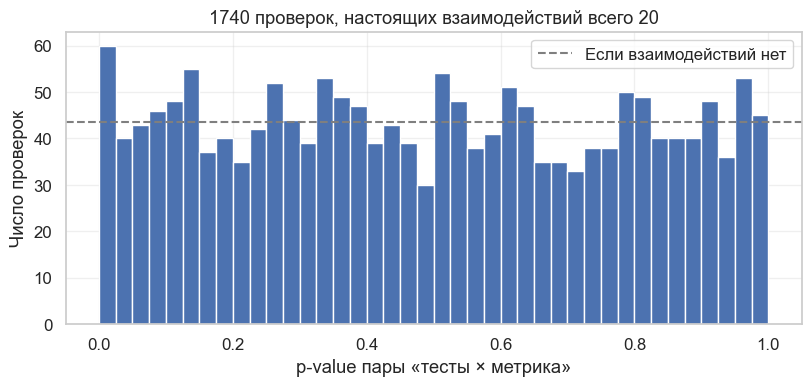

Всего проверок: 1740


,Найдено сильных,Найдено умеренных,Ложных
Метод,,,
p < 0.05,10,7,86.2
Бонферрони,9.6,0.5,0
Бенджамини — Хохберг,9.9,1.4,0.6


In [26]:
def all_pairs(n_tests=30, n_metrics=4, strong=10, moderate=10, reps=300, seed=3):
    """Проверка всех пар: у части пар есть настоящее взаимодействие, остальные чисто нулевые."""
    local = np.random.default_rng(seed)
    total = n_tests * (n_tests - 1) // 2 * n_metrics
    records, sample = [], None
    for _ in range(reps):
        shift = np.zeros(total)
        shift[:strong] = 6.0
        shift[strong:strong + moderate] = 2.5
        z = local.normal(shift, 1)
        p_values = 2 * stats.norm.sf(np.abs(z))
        sample = p_values
        for name, found in [('p < 0.05', p_values < ALPHA), ('Бонферрони', p_values < ALPHA / total),
                            ('Бенджамини — Хохберг', multipletests(p_values, ALPHA, 'fdr_bh')[0])]:
            real = strong + moderate
            records.append({'Метод': name, 'Найдено сильных': found[:strong].sum(), 'Найдено умеренных': found[strong:real].sum(),
                            'Ложных': found[real:].sum()})
    return pd.DataFrame(records).groupby('Метод', sort=False).mean(), sample, total


pair_table, pair_p, pair_total = all_pairs()
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.hist(pair_p, bins=40, range=(0, 1), color=BLUE)
ax.axhline(pair_total / 40, color=GRAY, ls='--', label='Если взаимодействий нет')
ax.set_xlabel('p-value пары «тесты × метрика»')
ax.set_ylabel('Число проверок')
ax.set_title(f'{pair_total} проверок, настоящих взаимодействий всего 20')
ax.legend()
plt.show()
print('Всего проверок:', pair_total)
pair_table.round(1)

Без поправок мы получаем 86 ложных срабатываний на 17 найденных настоящих: разбирать их некому. Поправка Бонферрони убирает ложные, но теряет умеренные: находится 0.5 из 10. Бенджамини — Хохберг чуть мягче: 1.4 из 10 при почти нулевых ложных. Microsoft применяет именно её. В любом случае автоматический перебор находит только сильные взаимодействия. Но именно они и важны для решений. Также здесь нет корреляции между метриками, которая в реальности уменьшает число независимых проверок.

Что показали реальные данные? **Microsoft** взяла четыре крупных продукта, по одному дню, каждый с сотнями тестов и миллионами пользователей, и проверила все пары тестов и метрик. На трёх продуктах аномально малых p-value не оказалось, на четвёртом 0.002% комбинаций, примерно 1 из 50 000. Ни в одном случае значимые эффекты не имели противоположных знаков. Kohavi ещё в 2009 году писал, что сильные взаимодействия редки, а опасения преувеличены. О том же говорят Statsig, опираясь на опыт Facebook, и Vista, где настоящее взаимодействие пока не нашли. Оговорки важные: это один день на продукт, мощность ограничена, а результат не обязан повторяться в вашем продукте. Microsoft советует провести такой анализ на своих данных.

Настоящие взаимодействия при этом бывают. У LinkedIn два теста улучшали тему письма, но получатель открывает только одно письмо, поэтому они конкурировали. Другой пример: красный текст на красном фоне. Такие случаи обычно видны заранее: **они происходят на одном экране, у одной команды, в одном сценарии**.

### Что значит взаимодействие для решения

Эффект, который измерен в пересечении, зависит от того, у какой доли пользователей включён другой тест:

$$
\text{эффект A} = \tau_A + s \cdot \Delta
$$

где $s$ — доля пользователей с включённым B.

In [27]:
scenarios = pd.DataFrame({
    'Эффект A отдельно': [0.20, 0.20, 0.20],
    'Эффект B отдельно': [0.20, 0.20, 0.20],
    'Δ': [0.00, -0.10, -0.50],
})
scenarios['A в пересечении с 50% B'] = scenarios['Эффект A отдельно'] + 0.5 * scenarios['Δ']
scenarios['A после раскатки B'] = scenarios['Эффект A отдельно'] + scenarios['Δ']
scenarios['Оба вместе'] = scenarios['Эффект A отдельно'] + scenarios['Эффект B отдельно'] + scenarios['Δ']
scenarios.index = ['Нет взаимодействия', 'Слабое', 'Конфликт']
scenarios.round(3)

,Эффект A отдельно,Эффект B отдельно,Δ,A в пересечении с 50% B,A после раскатки B,Оба вместе
Нет взаимодействия,0.2,0.2,0,0.2,0.2,0.4
Слабое,0.2,0.2,-0.1,0.15,0.1,0.3
Конфликт,0.2,0.2,-0.5,-0.05,-0.3,-0.1


При слабом взаимодействии меняется размер эффекта, но не решение: A выгоден и в пересечении, и после раскатки B, а оба вместе лучше, чем по отдельности. Нас волнует только третья строка, где смена знака. Измеренный эффект A станет −0.05, а оба вместе дадут −0.10, хотя по отдельности каждый полезен.

Заметьте: **изоляция от этого не спасает.** Если тесты изолированы, обе команды увидят +0.20 и раскатят изменения. Взаимодействие никуда не денется, оно просто проявится на всех пользователях уже после решения. Statsig приводит похожий пример с синей кнопкой на синем фоне. Пересечение, наоборот, покажет проблему до запуска.

### Изолировать или пересекать

Проведём собственный расчёт: его нет в источниках, и модель в нём упрощённая. Команда за период проверяет 20 идей на 2 млн пользователей. Истинные эффекты нормальны, их разброс составляет 0.5% от стандартного отклонения метрики, а у части пар есть взаимодействие вдвое больше этого разброса. Прирост тоже считаем в процентах от стандартного отклонения. Раскатываем значимые улучшения и считаем, какой реальный прирост получили, включая взаимодействия между раскатанными изменениями.

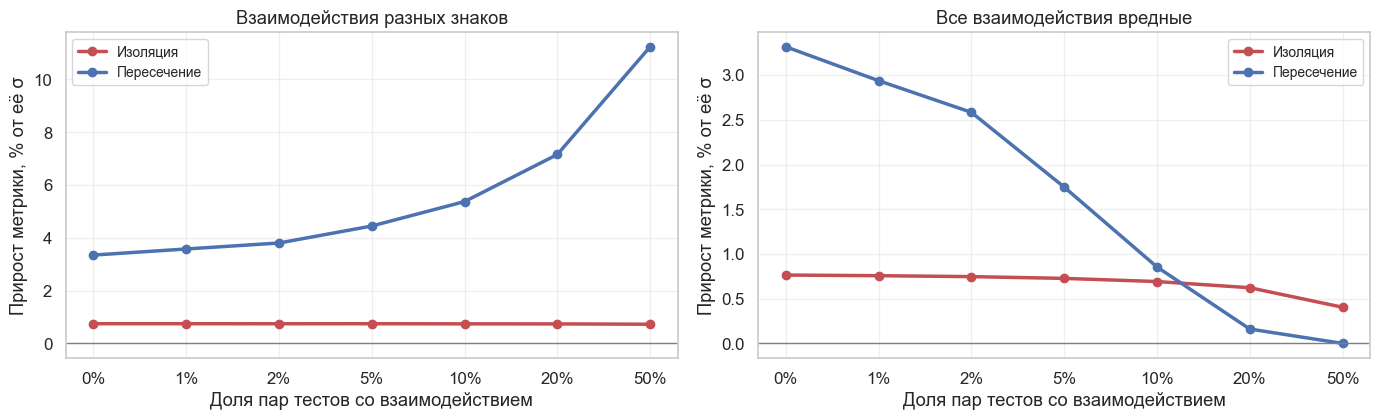

Изоляция  Пересечение
Знак     Доля пар                       
both     0             0.75         3.34
         0.01          0.75         3.58
         0.02          0.74          3.8
         0.05          0.75         4.44
         0.1           0.74         5.37
         0.2           0.74         7.15
         0.5           0.73        11.23
negative 0             0.76         3.32
         0.01          0.76         2.94
         0.02          0.75         2.58
         0.05          0.73         1.75
         0.1           0.69         0.85
         0.2           0.62         0.16
         0.5            0.4            0

In [28]:
def strategy_sim(p_interact, direction, n_tests=20, traffic=2_000_000, tau_sd=0.005, delta_size=0.01, reps=3000, seed=5):
    """Сравнивает прирост метрики от раскатанных тестов при изоляции и пересечении."""
    local = np.random.default_rng(seed)
    upper = np.triu_indices(n_tests, 1)
    se_overlap = 2 / np.sqrt(traffic)
    se_isolated = se_overlap * np.sqrt(n_tests)
    gains = {'Изоляция': [], 'Пересечение': []}
    for _ in range(reps):
        tau = local.normal(0, tau_sd, n_tests)
        delta = np.zeros((n_tests, n_tests))
        active = local.random(len(upper[0])) < p_interact
        signs = -1.0 if direction == 'negative' else local.choice([-1.0, 1.0], len(upper[0]))
        delta[upper] = active * signs * delta_size
        delta = delta + delta.T

        estimate_iso = tau + local.normal(0, se_isolated, n_tests)
        estimate_over = tau + 0.5 * delta.sum(axis=1) + local.normal(0, se_overlap, n_tests)
        for name, ship in [('Изоляция', estimate_iso / se_isolated > Z), ('Пересечение', estimate_over / se_overlap > Z)]:
            gains[name].append(tau[ship].sum() + delta[np.ix_(ship, ship)].sum() / 2)
    return {name: np.mean(values) for name, values in gains.items()}


rates = [0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
outcomes = {direction: pd.DataFrame({rate: strategy_sim(rate, direction) for rate in rates}).T * 100 for direction in ('both', 'negative')}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, (direction, title) in zip(axes, [('both', 'Взаимодействия разных знаков'), ('negative', 'Все взаимодействия вредные')]):
    for (name, column), color in zip(outcomes[direction].items(), [RED, BLUE]):
        ax.plot(range(len(rates)), column, color=color, lw=2.5, marker='o', label=name)
    ax.set_xticks(range(len(rates)), [f'{r:.0%}' for r in rates])
    ax.axhline(0, color=GRAY, lw=1)
    ax.set_xlabel('Доля пар тестов со взаимодействием')
    ax.set_ylabel('Прирост метрики, % от её σ')
    ax.set_title(title)
    ax.legend(fontsize=10)
plt.tight_layout()
plt.show()
pd.concat(outcomes, names=['Знак', 'Доля пар']).round(2)

In [29]:
def crossover(**params) -> str:
    # наименьшая доля вредных пар, при которой изоляция догоняет пересечение
    for rate in [0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]:
        gains = strategy_sim(rate, 'negative', reps=1500, **params)
        if gains['Изоляция'] >= gains['Пересечение']:
            return f'{rate:.0%}'
    return 'больше 50%'


settings = {'База: 20 тестов, 2 млн, Δ = 2σ эффекта': {}, 'Трафика в 10 раз больше': {'traffic': 20_000_000}, 'Трафика в 10 раз меньше': {'traffic': 200_000},
            'Δ вдвое меньше': {'delta_size': 0.005}, 'Δ вдвое больше': {'delta_size': 0.02}, '50 тестов': {'n_tests': 50}, '5 тестов': {'n_tests': 5}}
pd.Series({name: crossover(**params) for name, params in settings.items()}, name='Изоляция догоняет при доле пар').to_frame()

,Изоляция догоняет при доле пар
"База: 20 тестов, 2 млн, Δ = 2σ эффекта",20%
Трафика в 10 раз больше,5%
Трафика в 10 раз меньше,20%
Δ вдвое меньше,20%
Δ вдвое больше,10%
50 тестов,10%
5 тестов,50%


**Если знаки разные**, пересечение выигрывает всегда. Без взаимодействий прирост 3.3% от $\sigma$ метрики против 0.8%: разница в 4.5 раза, потому что у изолированных тестов слишком мало мощности, чтобы найти настоящие улучшения. Рост синей линии — следствие отбора: тесты с положительными взаимодействиями чаще проходят порог.

**Если все взаимодействия вредные** (худший случай для пересечения), синяя линия падает, но изоляция догоняет только при 10–20% вредных пар. Таблица показывает, что порог зависит от условий: от 5% при большом трафике до 50% при малом числе тестов. Логика простая: чем больше трафика, тем меньше изоляция теряет в мощности.

Сравните эти цифры с реальными: 0.002% у Microsoft. Вывод: **по умолчанию тесты пересекаем, а изолируем только пары, в которых конфликт ожидается заранее.** Именно так поступают Microsoft, LinkedIn и Statsig. Изоляция оправдана, когда пересечение технически невозможно (два алгоритма ранжирования одной выдачи), ломает опыт пользователя, или когда нужно точно измерить размер эффекта, а не только его направление.

Итоговая практика такая:

| Проверка | Когда | Что делаем при сигнале |
| :--- | :--- | :--- |
| Ортогональность, матрица всех пар | Автоматически | Ищем поломку сплита, результаты не используем |
| Обзор плана | До запуска, по экранам и сценариям | Разводим тесты по слоям или по времени |
| Аддитивность, $\Delta$ | Вручную для подозрительных пар | Смотрим, меняется ли решение |
| Все пары с поправкой | Если хватает трафика | Разбираем только сильные случаи |

## Надёжность платформы

Самая дорогая поломка платформы — та, которую никто не заметил. Поэтому платформа сама проверяет каждый тест. Методы мы разобрали в модуле 1, здесь важен взгляд со стороны платформы.

**SRM** (Sample Ratio Mismatch) — несовпадение фактического соотношения групп с запланированным. По данным Microsoft, он встречается примерно у 6% тестов, а у LinkedIn около 10% среди тестов с условием на вход. Причины делятся по стадиям:

| Стадия | Пример |
| :--- | :--- |
| Назначение | Неверные бакеты, плохие id, остаточный эффект |
| Выполнение | Редирект только в одном варианте, вариант меняет вовлечённость |
| Обработка логов | Неверные соединения таблиц, фильтр ботов |
| Анализ | Условие отбора зависит от варианта |
| В любой момент | Неравномерная раскатка, самостоятельный выбор варианта |

Microsoft разбирает случай MSN: увеличение числа карточек в карусели выглядело вредным, пока не выяснилось, что самых вовлечённых пользователей варианта отсеял фильтр ботов. После исправления эффект оказался положительным. Смоделируем похожую ситуацию: 1 млн пользователей, истинный эффект +2%, а 60% самых активных пользователей теста принимаются за ботов. Это всего 0.3% группы.

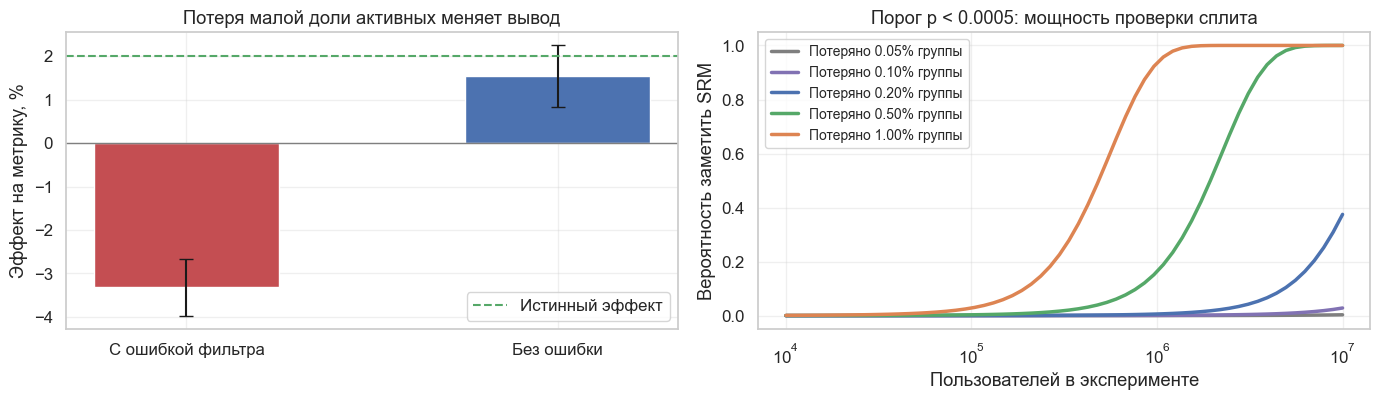

Вероятность заметить потерю 0.3% группы на 1 млн: 0.024


,"Тест, строк","Контроль, строк",SRM p-value,SRM в сегменте активных,"Разница средних, %",± 95%
С ошибкой фильтра,4.99e+05,4.995e+05,0.651,1.898e-69,-3.313,0.656
Без ошибки,5.005e+05,4.995e+05,0.2946,0.215,1.534,0.7101


In [30]:
def srm_p(n_test: int, n_control: int) -> float:
    return stats.chisquare([n_test, n_control]).pvalue


local = np.random.default_rng(11)
n_srm = 1_000_000
group = local.integers(0, 2, n_srm).astype(bool)
engagement = local.lognormal(0, 1.2, n_srm)
true_effect = 0.02
sessions = engagement * (1 + true_effect * group)

heavy = sessions >= np.quantile(sessions, 0.995)
bot_filter = group & heavy & (local.random(n_srm) < 0.6)        # в тесте активных приняли за ботов
clean = ~bot_filter
segment = engagement >= np.quantile(engagement, 0.99)            # активные по истории до теста


def srm_row(mask):
    n_test, n_control = (mask & group).sum(), (mask & ~group).sum()
    ratio = sessions[mask & group].mean() / sessions[mask & ~group].mean() - 1
    se = np.sqrt(sessions[mask & group].var() / n_test + sessions[mask & ~group].var() / n_control) / sessions[mask & ~group].mean()
    return {'Тест, строк': n_test, 'Контроль, строк': n_control, 'SRM p-value': srm_p(n_test, n_control),
            'SRM в сегменте активных': srm_p((mask & group & segment).sum(), (mask & ~group & segment).sum()),
            'Разница средних, %': ratio * 100, '± 95%': Z * se * 100}


before = pd.DataFrame({'С ошибкой фильтра': srm_row(clean), 'Без ошибки': srm_row(np.ones(n_srm, dtype=bool))}).T

losses = np.array([0.0005, 0.001, 0.002, 0.005, 0.01])
sizes = np.geomspace(1e4, 1e7, 60)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
bars = before['Разница средних, %']
axes[0].bar(bars.index, bars, yerr=before['± 95%'], color=[RED, BLUE], width=0.5, capsize=5)
axes[0].axhline(true_effect * 100, color=GREEN, ls='--', label='Истинный эффект')
axes[0].axhline(0, color=GRAY, lw=1)
axes[0].set_ylabel('Эффект на метрику, %')
axes[0].set_title('Потеря малой доли активных меняет вывод')
axes[0].legend()
threshold = stats.chi2.isf(0.0005, 1)
for loss, color in zip(losses, [GRAY, PURPLE, BLUE, GREEN, ORANGE]):
    noncentrality = sizes * loss ** 2 / 4
    axes[1].plot(sizes, stats.ncx2.sf(threshold, 1, noncentrality), color=color, lw=2.5, label=f'Потеряно {loss:.2%} группы')
axes[1].set_xscale('log')
axes[1].set_xlabel('Пользователей в эксперименте')
axes[1].set_ylabel('Вероятность заметить SRM')
axes[1].set_title('Порог p < 0.0005: мощность проверки сплита')
axes[1].legend(fontsize=10)
plt.tight_layout()
plt.show()
print(f'Вероятность заметить потерю 0.3% группы на 1 млн: {stats.ncx2.sf(threshold, 1, 1e6 * 0.003 ** 2 / 4):.3f}')
before

Поломка меняет знак вывода с +1.5% на −3.3%, потому что у метрики тяжёлый хвост, а **общий SRM молчит** ($p = 0.65$). Это не случайность: при таком размере теста порог 0.0005 замечает потерю 0.3% группы лишь в 2.4% случаев, что видно и на графике справа. Потери вообще мало заметны, пока они не достигают примерно полпроцента на миллионах пользователей.

Выручает **SRM по сегментам**: среди пользователей, активных ещё до теста, расхождение огромно ($p \approx 10^{-69}$). Microsoft отмечает, что SRM бывает локальным, например только в одном браузере. Сегменты должны быть заданы данными до начала теста, иначе отбор сам создаст перекос.

Порог Microsoft $p < 0.0005$ нужен потому, что платформа проверяет каждый тест.

In [31]:
n_tests_year = 1000
pd.DataFrame({'Порог': [0.05, 0.001, 0.0005],
              'Ложных тревог на 1000 тестов': [n_tests_year * threshold_ for threshold_ in (0.05, 0.001, 0.0005)]}).set_index('Порог').round(1)

,Ложных тревог на 1000 тестов
Порог,
0.05,50
0.001,1
0.0005,0.5


При 1000 тестах в год порог 0.05 дал бы 50 ложных тревог, и им быстро перестали бы верить. Остальные постоянные проверки на платформе: A/A на множестве солей при каждом изменении сплита, ортогональность всех пар, защитные метрики и автоматическая остановка опасных тестов, сравнение показателей до начала теста.

Spotify, например, проверяет соотношение групп, различия в активности до воздействия, падения клиента и конфликты свойств.

## Культура и процесс

Платформа делает запуск дешёвым, но решения принимают люди. В обзоре саммита 2019 года, где собрались представители 13 компаний, культура названа отдельной большой проблемой.

**Интуиция ошибается.** В кейсах Microsoft треть идей значимо улучшала ключевые метрики, а ещё треть значимо ухудшала. Похожие результаты приводят и другие компании. Поэтому отрицательный результат надо считать успехом: он спас продукт от вреда.

В обзоре описан путь изменения команды: сначала уверенность, что каждая идея хороша, затем скепсис, когда эксперименты начинают спорить с интуицией, а потом спокойное отношение к тому, что идеи часто не работают. Kohavi и соавторы называют главного противника HiPPO: мнение самого высокооплачиваемого сотрудника.

| Практика | Зачем |
| :--- | :--- |
| План фиксируем до запуска: гипотеза, метрики, длительность, правило решения | Чтобы не подгонять выводы под результат |
| Общая метрика (OEC): одна или несколько ключевых | Связывает решения команд с целью компании |
| Защитные метрики | Победа по одной метрике не должна портить продукт |
| Ревью экспериментов опытными коллегами | Находит ошибки дизайна до потери трафика |
| Постепенная раскатка | Ограничивает вред от ошибки, так поступают Google и Microsoft |
| Обратная группа (holdback) | Измеряет накопленный эффект: у Spotify так проверяют итог кварталов |
| Каталог прошлых тестов | Команды учатся на чужих результатах, этому помогает мета-анализ из лекции 3.01 |
| Обучение и доступность | Эксперименты запускают и неинженеры: авторы статьи Google отмечают рост их числа |

Польза метрики тоже проверяема: OEC должна быть связана с долгосрочными целями компании и быть чувствительной, то есть реагировать на изменения.

## Кейсы компаний

Что почитать дальше и зачем. Цифры относятся к моменту публикации.

**Как построить слои**

* [Google: Overlapping Experiment Infrastructure](https://research.google/pubs/pub36500/). С этой статьи начались слои. Одного слоя экспериментов стало мало: тестов не хватало трафика. Команда разделила параметры системы на слои и домены и получила почти на порядок больше экспериментов. Читать, чтобы увидеть полную схему, включая launch layers и то, как статья связывает инфраструктуру с обучением и инструментами.
* [LinkedIn: From Infrastructure to Culture](https://engineering.linkedin.com/data/publications/resources/2015/from-infrastructure-to-culture-a-b-testing-challenges). Обратная позиция: без слоёв, всё пересекается по умолчанию. Читать ради того, как при таком подходе разводят конфликты через `gating key` и как платформа меняет культуру компании.

**Как перейти от случайных бакетов к постоянным**

* Spotify: [платформа, часть 2](https://engineering.atspotify.com/2020/11/spotifys-new-experimentation-platform-part-2/) и [стратегия координации](https://engineering.atspotify.com/2021/03/10/spotifys-new-experimentation-coordination-strategy/). Как запускать тесты в любой момент и не накапливать остаточные эффекты. Читать обе подряд: вторая статья заменяет решение из первой.

**Нужно ли бояться пересечений**

* [Microsoft: A/B Interactions: A Call to Relax](https://www.microsoft.com/en-us/research/articles/a-b-interactions-a-call-to-relax/). Главный источник цифр из этой лекции. Читать как образец: это короткий рецепт, как повторить такой анализ на своих данных.
* [Statsig: Embracing Overlapping A/B Tests](https://statsig.com/blog/embracing-overlapping-a-b-tests-and-the-danger-of-isolating-experiments). Аргументы против изоляции от бывшего сотрудника Facebook. Читать, если нужно убедить команду, и ради списка случаев, когда изоляция всё же оправдана.
* [Vermeer: Detecting Interaction Effects](https://www.lukasvermeer.nl/publications/2023/06/26/detecting-interaction-effects-in-online-experimentation.html). Простой порядок действий с кодом: χ² по трафику, затем регрессия. Читать, чтобы внедрить проверку за день.
* [hh: Пересекающиеся эксперименты](https://habr.com/ru/companies/hh/articles/1084724/). Русскоязычный разбор. Читать, потому что в нём честно объяснено, почему от автоматической проверки всех пар отказались и что сделали вместо неё.

**Как построить платформу с нуля**

* [Ozon: высоконагруженная платформа](https://habr.com/ru/companies/ozontech/articles/689052/). История от Excel до хеша с солью. Читать ради того, какие проблемы вскрываются на каждом шаге роста.
* [Delivery Club: автоматизация A/B-тестов](https://habr.com/ru/post/557308). Отказ от готового решения: в Firebase около 30% пользователей меняли группу. Читать как пример, зачем проверять сторонний инструмент.

**Как ловить поломки**

* [Microsoft: Diagnosing Sample Ratio Mismatch](https://www.microsoft.com/en-us/research/articles/diagnosing-sample-ratio-mismatch-in-a-b-testing/). Таксономия причин SRM с примерами. Читать как справочник на случай, когда SRM сработал.

Открытых описаний сплитования у Авито и Wildberries мы не нашли.

## Заключение

* Платформа делает запуск тестов дешёвым и автоматизирует проверки. Сами методы при этом те же, что в модуле 1.
* Группа вычисляется из `id`, поэтому её не надо хранить. Хеш убирает зашитую в `id` историю пользователя, бакеты задают долю трафика, а соль делает разбиения разных тестов независимыми. Внутри потока нужен двойной посол.
* Хеш надо проверять вместе с правилом и форматом id. У CRC32 и Java `hashCode` при `% 2` разные соли дают одинаковые группы, а SRM при этом идеальный.
* **Ортогональность** — дешёвая проверка сплита, её стоит запускать для всех пар. Поломка загрязняет главный эффект, а не создаёт ложное взаимодействие.
* **Аддитивность** проверяется регрессией `y ~ a * b`, но требует в 4 раза больше данных и зависит от шкалы. Отсутствие сигнала не доказывает отсутствия взаимодействия.
* Настоящие взаимодействия редки: 0.002% и меньше у Microsoft. В нашем расчёте изоляция догоняет пересечение только при 5–50% вредных пар, а в остальных случаях проигрывает из-за потери мощности.
* Изоляция не убирает взаимодействие, а прячет его до раскатки.
* SRM обязателен, но слеп к малым потерям. Потеря 0.3% активных меняет знак вывода, поэтому нужны сегменты, заданные до теста.
* Платформа без культуры бесполезна: идеи часто не работают, и это нормально.

**Чек-лист платформы**

1. Назначение детерминировано, группа не меняется при входе в аккаунт.
2. Хеш проверен на своих id и своём правиле: равномерность, независимость солей, много A/A.
3. У каждого теста или слоя своя соль, внутри потока двойной посол.
4. Хеш считается одинаково в продукте и в аналитике.
5. Ортогональность всех пар проверяется автоматически, SRM обязателен и считается также по сегментам.
6. Перед запуском смотрим пересечения по экранам и сценариям, конфликты разводим слоями.
7. Подозрительные пары проверяем на взаимодействие, с поправкой на множественность и с расчётом мощности.
8. Новый тест не использует бакеты только что завершённого без проверки остаточного эффекта.
9. Правило решения зафиксировано до запуска, есть защитные метрики и журнал прошлых тестов.